# TIMSS mathematics items answered by LLMs, scored with IRT

How well do LLMs answer the released TIMSS mathematics items, and where do they stand on the IRT and reporting scales of TIMSS?

A condition is an LLM with its settings, such as its reasoning effort, and the role it takes:

- `"test_taker"`: the LLM takes the test written for students of a grade, and its answers evaluate the LLM.
- `"student"`: the LLM takes the test as a student of that grade, and is used as a participant.

Every condition answers the same items with the same prompts, apart from the role.
The analysis has five LLMs, each in both roles, so ten conditions: `gpt-6-luna` without and with high reasoning and `gemma-3-12b-it` through OpenRouter, and Claude Haiku 5.5 without thinking and with its default thinking through the Claude API.

1. Group the released items that have IRT parameters into units, the items a student sees together (`ItemUnits`): an item alone, or all items of a multi-part item or shared-stimulus task, in booklet order.
2. Ask every condition to answer every unit (`Administration.request_answers_async`), with a system prompt that names the test and its grade (fourth, eighth, or twelfth grade, the last for TIMSS Advanced) and the role.
   Requests go as OpenRouter batches, at about half the price, for the models that have them, and directly otherwise; both run with `async` and `await`, all conditions at once.
3. Score each answer: a multiple-choice answer against the item's official answer key, and a constructed response by an LLM scorer with the item's scoring guide (`request_verdicts_async` and `scores`).
4. Score each condition with the IRT models and the calibrated parameters (`results`): each item score on the IRT scale, and the ability θ of each condition on each calibration's scale (EAP and maximum likelihood), also as a TIMSS scale score with the calibration's linear transformation constants.
5. Draw the scores (`plots`), and export everything to a workbook.
6. Use the answers in two ways: as **a benchmark**, the LLMs as test takers, and as **synthetic data**, the LLMs as students, checked against what is known about real students.

The code is in the package, `timss_math.llm_test_taking`; this notebook sets it up, runs it, and shows every step.

### How to use this notebook

- **Run all cells as they are.**
  The notebook reads the saved answers and verdicts of the run of 2026-10-19 and reproduces its results, without API keys and without any request.
- **To test other LLMs, change the Settings cell and run all cells again.**
  Add LLMs to `MODELS` (or replace them), set `MAX_REQUESTS = 1` for a test request per condition, then `None` for every unit; answers and verdicts are saved as they arrive, so a rerun requests only what is missing, and the saved ones cost nothing.
  Requests need the provider's API key in `.env` at the root of the repository (`OPENROUTER_API_KEY`, `ANTHROPIC_API_KEY`, ...).
- **From the command line**, the same runs without a notebook: `uv run timss-llm-test --help`.

Run it with its own folder as the working directory (VS Code's default); `DATA_DIR` is `notebooks/data/`.
The answers and the scorer's verdicts are saved as JSON in `data/cache/llm_answers/` and `data/cache/llm_answer_scores/`.

In [1]:
import asyncio
import itertools
import json
import logging
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.figure import Figure
from scipy import stats

from timss_math import plot_style
from timss_math.items import DUPLICATE_ITEMS, GRADE_SHORT_NAMES
from timss_math.llm_test_taking import Administration, ItemUnits, LLMSettings, conditions_of, plots
from timss_math.llm_test_taking.answering import answer_schema, answer_system_prompt, answer_user_prompt
from timss_math.llm_test_taking.scoring import check_keys_and_guides

# The modules report their progress, such as submitted batches, through logging; one line per HTTP request would be
# too many.
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
for name in ("httpx", "httpx2"):
    logging.getLogger(name).setLevel(logging.WARNING)

# The graphs are matplotlib Figures drawn without pyplot, so the inline backend must be turned on to show them.
%matplotlib inline

DATA_DIR = Path.cwd() / "data"

## Settings

Change these to test other LLMs, roles, or scorers; the cells below need no change.

- `MODELS`: the LLMs that take the test, each an `LLMSettings`: `provider` (`"openrouter"`, the default, `"openai"`, `"gemini"`, `"anthropic"`, or `"ollama"` for a local model), `model`, `reasoning_effort` (such as `"none"`, `"low"`, `"medium"`, or `"high"`; `None` sends none), `max_tokens` (16,384 by default, reasoning included), and how it is called (`base_url`, `timeout`, `max_retries`, `ollama_num_ctx`).
  The five LLMs of the run of 2026-10-19 have saved answers; the section on conditions describes them, their prices, and what each provider allows.
- `MORE_MODELS`: more LLMs with some saved answers, left out of the analysis; move one into `MODELS` to add it.
- `ROLES`: `"test_taker"`, `"student"`, or both; every model takes the test in every role.
- `SCORER`: the LLM that scores the constructed responses of every condition, so that all are scored alike.
- `MAX_REQUESTS` (units per condition) and `SCORER_MAX_REQUESTS` (verdicts): requests cost money, so at 0, their default, the notebook only reads what is saved (and collects the batches that an earlier run submitted); 1 is a test request, and `None` requests everything missing.
- `REQUEST_MODE` and `SCORER_REQUEST_MODE`: `"batch"` (OpenRouter batches for the models that have them, at about half the price, which can take up to 24 hours, and direct requests for the others) or `"direct"` (every request now); `BATCH_WAIT` waits until every batch is collected, and otherwise a later run collects them.
- `WORKBOOK`: where the results go; give it another name when you test other LLMs, so that the workbook of the run of 2026-10-19 stays as it is.

In [2]:
# The LLMs of the analysis: gpt-6-luna and gemma-3-12b-it through OpenRouter, and Claude Haiku 5.5 through the Claude
# API (ANTHROPIC_API_KEY), with thinking off ("none") or left to the model (None, adaptive at its default effort).
MODELS = [
    LLMSettings(model="openai/gpt-6-luna", reasoning_effort="none"),
    LLMSettings(model="openai/gpt-6-luna", reasoning_effort="high"),
    LLMSettings(model="google/gemma-3-12b-it", reasoning_effort=None),
    LLMSettings(provider="anthropic", model="claude-haiku-5-5", reasoning_effort="none"),
    LLMSettings(provider="anthropic", model="claude-haiku-5-5", reasoning_effort=None),
]
# More LLMs, left out of the analysis for now: move one into MODELS to add its conditions. Their saved answers are
# reused, and every run collects their open batches without requesting anything new.
MORE_MODELS = [
    LLMSettings(model="google/gemini-3.8-flash", reasoning_effort="minimal"),
    LLMSettings(model="google/gemini-3.8-flash", reasoning_effort="high"),
    LLMSettings(model="anthropic/claude-haiku-5.5", reasoning_effort="none"),  # Claude Haiku 5.5 through OpenRouter
    LLMSettings(model="anthropic/claude-haiku-5.5", reasoning_effort="high"),
    LLMSettings(model="openai/gpt-4o-mini", reasoning_effort=None),
    # A local model in Ollama costs nothing but takes hours for every unit:
    # LLMSettings(provider="ollama", model="llama3.2", reasoning_effort=None, max_tokens=4096),
]
ROLES = ["test_taker", "student"]  # every model takes the test written for its grade, and as a student of it
SCORER = LLMSettings(model="google/gemini-3.8-flash", reasoning_effort="medium", max_tokens=8192)

MAX_REQUESTS = 0  # units per condition and run: 0 only collects open batches, 1 is a test, None requests every missing unit
REQUEST_MODE = "batch"  # "batch": OpenRouter batches where the model has them, else direct; "direct": every request now
BATCH_WAIT = False  # True: wait until every batch is collected (up to 24 hours)
SCORER_MAX_REQUESTS = 0  # verdicts per run: 0 only collects open batches, 1 is a test, None requests every missing verdict
SCORER_REQUEST_MODE = "direct"  # "direct": every verdict now; "batch": OpenRouter batches, at half the price but slower

WORKBOOK = DATA_DIR / "timss_math_llm_answers_scored.xlsx"

## Items and units

The items and their parameters come from the package's data: the 731 released items (`ItemUnits.load`), and the calibrated parameters of the 724 that have them.
These include the three items whose stem and options repeat another item's (K7 of TIMSS 1995 grade 4, D11 of TIMSS 1999 grade 8, and L15B of TIMSS Advanced 1995), which the prediction index leaves out; here each is an item of its own test, and L15B has no parameters anyway.

A unit is what a student sees together: an item alone, or all parts of a multi-part item and all items of a shared-stimulus task (`SHARED_STIMULUS_TASKS`), in booklet order.
Later parts often depend on earlier ones ("Trading Cards (Continued)", or "What fraction of the figure is shaded in part B above?"), and many repeat only part of the shared stimulus, so a unit is asked in one request, with one answer per item.
A unit without any calibrated item is not asked; an uncalibrated item of a unit that is asked is answered with it but not scored.

In [3]:
units = ItemUnits.load()  # the 731 released items, the parameters of the 724 that have them, and their units
several = sum(len(unit.item_keys) > 1 for unit in units.units)
print(f"{len(units.units)} units hold the {len(units.parameters)} calibrated items; {several} units have several items")
print("Answered with their unit but not scored:", [key for key in units.unit_of_item if key not in units.parameters.index] or "none")
print("Not asked, without any calibrated item:", [unit.key for unit in units.all_units if unit not in units.units])
display(units.summary())

652 units hold the 724 calibrated items; 39 units have several items
Answered with their unit but not scored: none
Not asked, without any calibrated item: ['TIMSS Advanced 1995/grade 12/Advanced Mathematics/K8', 'TIMSS Advanced 1995/grade 12/Advanced Mathematics/K9', 'TIMSS Advanced 1995/grade 12/Advanced Mathematics/L10', 'TIMSS Advanced 1995/grade 12/Advanced Mathematics/L11', 'TIMSS Advanced 1995/grade 12/Advanced Mathematics/L15A+L15B', 'TIMSS 2007/grade 8/Mathematics/M042273']


units  units_of_several_items  items  \
grade assessment                                                  
4     TIMSS 1995              65                       4     70   
      TIMSS 2003              68                       5     79   
      TIMSS 2007              66                       4     74   
      TIMSS 2011              65                       5     73   
8     TIMSS 1999              79                       2     82   
      TIMSS 2003              90                       5     99   
      TIMSS 2007              74                       6     88   
      TIMSS 2011              77                       5     88   
12    TIMSS Advanced 1995     31                       0     31   
      TIMSS Advanced 2008     37                       3     40   

                           calibrated_items  
grade assessment                             
4     TIMSS 1995                         70  
      TIMSS 2003                         79  
      TIMSS 2007                         74  
      TIMSS 2011                         73  
8     TIMSS 1999                         82  
      TIMSS 2003                         99  
      TIMSS 2007                         88  
      TIMSS 2011                         88  
12    TIMSS Advanced 1995                31  
      TIMSS Advanced 2008                40

## Prompts

The system prompt names the test and its grade, in one of two roles:

- `"test_taker"` (evaluating the LLM): "You are taking the TIMSS mathematics test for students in the fourth grade. Answer each question as well as you can."
  It asks for the LLM's best answers to a test written for that grade, without asking it to act as a student, which would invite made-up mistakes.
- `"student"` (the LLM as a participant): "You are a fourth-grade student taking the TIMSS mathematics test for students in your grade. Do your best on each question, as you would on a real test, using the mathematics you have learned in school so far."
  It asks the LLM to answer as a student of that grade, with what such a student has learned, but never to make mistakes on purpose.

The grade is the fourth or the eighth, or the twelfth for TIMSS Advanced: "the TIMSS Advanced mathematics test for students in the twelfth grade, the final year of secondary school, who have taken advanced mathematics courses".
The rest of the system prompt, the same in both roles, says how the paper test is given as text: figures are described in words and tables written out, a drawing is answered by describing it, and work or an explanation goes into the answer when the question asks for it.

The user prompt is the unit: for each item its stem, its figure described in words (as `get_data.ipynb` transcribed it with `gemini-3.8-flash`), and its options, numbered in booklet order in a unit of several items.
It never holds the item's ID, classification, answer key, scoring guide, or statistics.

The answer comes back as structured output: for each item, the letter of an option for a multiple-choice item, or the written answer, with any work, explanation, or description of a drawing that the item asks for.
No field asks for reasoning, so how much an LLM thinks before it answers is set by its reasoning effort alone.

The module `answering` holds the prompts and the schema; any change there asks every unit again.

In [4]:
for role in ("test_taker", "student"):
    for grade in (4, 12):
        print(f"----- system prompt, {role}, grade {grade}\n{answer_system_prompt(grade, role)}\n")
for key in ("TIMSS 1995/grade 4/Mathematics/I3", "TIMSS 2011/grade 8/Mathematics/M042198B"):
    example = units.unit_of_item[key]
    print(f"========== {example.key}\n----- user prompt\n{answer_user_prompt(example)}")
    print(f"----- output schema\n{json.dumps(answer_schema(example).model_json_schema()['properties'], indent=1)}\n")

----- system prompt, test_taker, grade 4
You are taking the TIMSS mathematics test for students in the fourth grade. Answer each question as well as you can.

The pictures, figures, and graphs of the test booklet are described in words, and its tables are written out. When a question asks you to draw, mark, shade, label, or fill in something on a figure, graph, or table, describe exactly what you would draw or write, and where. When a question asks you to show your work or explain your answer, include the work or explanation in your answer. For a multiple-choice question, choose one option.

----- system prompt, test_taker, grade 12
You are taking the TIMSS Advanced mathematics test for students in the twelfth grade, the final year of secondary school, who have taken advanced mathematics courses. Answer each question as well as you can.

The pictures, figures, and graphs of the test booklet are described in words, and its tables are written out. When a question asks you to draw, mark, 

## Conditions

A condition (`Condition`) is an LLM and its settings, the package's `LLMSettings` (provider, model, reasoning effort, and `max_tokens`, 16,384 by default, reasoning included), and a role.
`MODELS` lists the LLMs of the analysis and `ROLES` the roles; every model takes the test in every role (`conditions_of`), so `ROLES = ["test_taker", "student"]` doubles the conditions, and each condition's label ends in ", as a student" in the student role.
`MORE_MODELS` lists the other LLMs tried so far, left out of the analysis for now, in an `Administration` of their own (`more`): moving one into `MODELS` adds its conditions, reusing the answers saved for them and requesting the rest, and every run collects the open batches of `MORE_MODELS` without requesting anything new for them, so their answers keep being saved for later.
The analysis has five LLMs, each in both roles (`ROLES = ["test_taker", "student"]`), so ten conditions: `openai/gpt-6-luna` without and with high reasoning and `google/gemma-3-12b-it` through OpenRouter, and `claude-haiku-5-5` through the Claude API (provider `"anthropic"`), without thinking and with its default thinking, the two settings that API allows (see below).
`MORE_MODELS` keeps `google/gemini-3.8-flash` (minimal and high reasoning), `anthropic/claude-haiku-5.5` through OpenRouter (no and high reasoning), and `openai/gpt-4o-mini`: the batches of 2026-10-18 saved every answer of the two OpenRouter Haiku conditions and about 200 of each Gemini condition, and `gpt-4o-mini` has a test answer only.

| Model | Provider | Price per million tokens (input / output), direct and in batches | Reasoning efforts | List |
| --- | --- | --- | --- | --- |
| `openai/gpt-6-luna` | OpenRouter | $0.10 / $0.50, batch $0.05 / $0.25 | none, high | `MODELS` |
| `google/gemma-3-12b-it` | OpenRouter | $0.05 / $0.15, no batches | no reasoning setting (`None`) | `MODELS` |
| `claude-haiku-5-5` | Claude API | $0.10 / $0.50 (prompts up to 100,000 tokens), no batches through the OpenAI SDK | none, or the model's default (`None`: adaptive thinking at its default effort) | `MODELS` |
| `google/gemini-3.8-flash` | OpenRouter | $0.825 / $4.125, batch $0.375 / $1.875 | minimal, high (it cannot turn reasoning off: OpenRouter answers `"none"` with HTTP 400) | `MORE_MODELS` |
| `anthropic/claude-haiku-5.5` | OpenRouter | $0.10 / $0.50, batch $0.05 / $0.25 | none, high (it reasons only as much as a question needs, even at high) | `MORE_MODELS` |
| `openai/gpt-4o-mini` | OpenRouter | $0.15 / $0.60; OpenRouter lists a batch variant ($0.075 / $0.30) but rejects its batches ("does not have a :batch endpoint", 2026-10-18), so it is asked directly | no reasoning setting | `MORE_MODELS` |

`meta-llama/llama-3.1-8b-instruct` was tried and left out: on 2026-10-17 it did not finish a structured answer to a one-line question within 8,000 tokens.
Any other provider of `LLMSettings` works too, always asked directly, never in batches: `"openai"`, `"gemini"`, `"anthropic"`, and `"ollama"`, the first three through the OpenAI SDK.
`"anthropic"` asks Claude through the Claude API's OpenAI-compatible endpoint, with `ANTHROPIC_API_KEY` in `.env` and model IDs such as `claude-haiku-5-5`.
That endpoint follows the output schema but ignores `reasoning_effort` and rejects adaptive thinking, so a Claude model's `reasoning_effort` is `None`, which leaves thinking to the model (Claude 5 models think adaptively at their default effort), or `"none"`, which turns thinking off (`claude-haiku-5-5` allows it; Claude Opus 5.5 and Sonnet 5.5 answer HTTP 400); `anthropic/claude-haiku-5.5` through OpenRouter takes every effort level.
Providers other than OpenRouter report the tokens of a request but not its cost, so the cost of a condition is computed from its tokens at the prices of `TOKEN_PRICES` (thinking tokens are billed as output; `Administration(token_prices=...)` replaces the prices), or left empty for a model without a price there (a local Ollama model costs nothing).
A condition's label names its provider when it is not OpenRouter, and a Claude model without a reasoning setting thinks, so its label says so: "claude-haiku-5-5 (anthropic), no reasoning" and "claude-haiku-5-5 (anthropic), default thinking".

Each condition saves its answers in `data/cache/llm_answers/<provider>/<model>/<reasoning effort>/<role>/` (`default` for no reasoning setting, because this computer's file system ignores case, so a folder `None` would be the folder `none` of the same model), one JSON file per unit, named by the unit and a hash of the model, reasoning effort, both prompts, and the output schema, so that a changed prompt asks again.

One LLM scorer, `SCORER`, scores the constructed responses of every condition, so that all conditions are scored alike (see below); its `max_tokens` is lower (8,192), because OpenRouter reserves a batch's worst case, every request using all of it.

`DEFAULT_MODELS` and `DEFAULT_SCORER` of the package are `MODELS` and `SCORER` here, so `Administration()` alone is the analysis below.

In [5]:
administration = Administration(conditions_of(MODELS, ROLES), SCORER, units, data_dir=DATA_DIR)
more = Administration(conditions_of(MORE_MODELS, ROLES), SCORER, units, data_dir=DATA_DIR)  # only their open batches are collected
if set(administration.conditions) & set(more.conditions):
    raise ValueError(f"In both MODELS and MORE_MODELS: {sorted(set(administration.conditions) & set(more.conditions))}")
display(
    pd.DataFrame(
        [
            {
                "condition": label,
                "in_analysis": label in administration.conditions,
                "provider": condition.llm.provider,
                "model": condition.llm.model,
                "reasoning_effort": condition.llm.reasoning_effort,
                "role": condition.role,
            }
            for label, condition in (administration.conditions | more.conditions).items()
        ]
    )
)

,condition,in_analysis,provider,model,reasoning_effort,role
0,"gpt-6-luna, no reasoning",True,openrouter,openai/gpt-6-luna,none,test_taker
1,"gpt-6-luna, high reasoning",True,openrouter,openai/gpt-6-luna,high,test_taker
2,gemma-3-12b-it,True,openrouter,google/gemma-3-12b-it,NaN,test_taker
3,"claude-haiku-5-5 (anthropic), no reasoning",True,anthropic,claude-haiku-5-5,none,test_taker
4,"claude-haiku-5-5 (anthropic), default thinking",True,anthropic,claude-haiku-5-5,NaN,test_taker
5,"gpt-6-luna, no reasoning, as a student",True,openrouter,openai/gpt-6-luna,none,student
6,"gpt-6-luna, high reasoning, as a student",True,openrouter,openai/gpt-6-luna,high,student
7,"gemma-3-12b-it, as a student",True,openrouter,google/gemma-3-12b-it,NaN,student
8,"claude-haiku-5-5 (anthropic), no reasoning, as...",True,anthropic,claude-haiku-5-5,none,student
9,"claude-haiku-5-5 (anthropic), default thinking...",True,anthropic,claude-haiku-5-5,NaN,student


### Requests, direct and in batches

The module `requesting` sends the requests.
A `Request` is a system prompt, a user prompt, an output schema, and the JSON file where its output is saved, named by a hash of everything sent, so that a saved output is reused only for the same request.
`send` sends the requests of one LLM that have no saved output, at most `max_requests` of them (`None` for all, 0 for none), in one of two ways:

- `"direct"`: the requests go now, `workers` at a time (8) through the package's async client (`LLMClient.session`), and each output is saved as soon as it arrives.
- `"batch"`: the requests go as OpenRouter batches through the package's `OpenRouterBatches` (the Batch API, at about half the price, which can take up to 24 hours) for the models that OpenRouter batches (a `:batch` variant in its model list), and directly for the other models and for every other provider.
  A model whose batch OpenRouter rejects although its list has a `:batch` variant (HTTP 400, "does not have a :batch endpoint", as for `gpt-4o-mini`) is asked directly too.
  Every run first collects the batches that earlier runs submitted, then submits new ones; with `BATCH_WAIT` (`wait`), it polls every `poll_seconds` (60) until all are collected, and otherwise returns at once, so a later run (with `MAX_REQUESTS = 0`) collects them.
  `BatchManifests` keeps a manifest of every submitted batch in the `batches/` folder of the condition's cache, locked while a process submits or collects, so an interrupted run collects its batches instead of paying for them again; never delete an open manifest (`<batch id>.json` or `submitting-*.json`).
  Google models need the same output schema for every request of a batch, so their requests are batched by schema; a batch holds at most `batch_size` requests (200).
  OpenRouter reserves a batch's worst case, every request using all its `max_tokens`, against the key's balance until it completes, and answers HTTP 402 if it does not fit: 200 requests of `gemini-3.8-flash` reserve about $6, so submit large runs in parts.

Both ways run in `async` functions: the conditions run at once in an `asyncio.TaskGroup`, direct requests are awaited on the async client, and the blocking batch calls run in threads (`asyncio.to_thread`) with `asyncio.sleep` between polls.
Output that cannot be used (cut off at `max_tokens`, not fitting the schema, or missing) is reported and requested again on the next run; any other error, such as an API error from exhausted credit, stops the run, and what was saved or submitted until then stays saved.

`Administration.usage` gives each condition's settings, the units answered and in open batches, and the tokens, time, and cost of its answers.

In [6]:
usage_columns = ["provider", "model", "reasoning_effort", "role", "units", "answered_units", "in_open_batches", "direct_cost_usd", "batch_cost_usd"]
display(administration.usage()[usage_columns])

,provider,model,reasoning_effort,role,units,answered_units,in_open_batches,direct_cost_usd,batch_cost_usd
condition,,,,,,,,,
"gpt-6-luna, no reasoning",openrouter,openai/gpt-6-luna,none,test_taker,652,652,0,0.000393,0.027968
"gpt-6-luna, high reasoning",openrouter,openai/gpt-6-luna,high,test_taker,652,652,0,0.000046,0.042618
gemma-3-12b-it,openrouter,google/gemma-3-12b-it,NaN,test_taker,652,652,0,0.017402,0.000000
"claude-haiku-5-5 (anthropic), no reasoning",anthropic,claude-haiku-5-5,none,test_taker,652,652,0,0.065116,0.000000
"claude-haiku-5-5 (anthropic), default thinking",anthropic,claude-haiku-5-5,NaN,test_taker,652,652,0,0.110302,0.000000
"gpt-6-luna, no reasoning, as a student",openrouter,openai/gpt-6-luna,none,student,652,652,0,0.000000,0.016618
"gpt-6-luna, high reasoning, as a student",openrouter,openai/gpt-6-luna,high,student,652,652,0,0.000000,0.038769
"gemma-3-12b-it, as a student",openrouter,google/gemma-3-12b-it,NaN,student,652,651,0,0.024336,0.000000
"claude-haiku-5-5 (anthropic), no reasoning, as a student",anthropic,claude-haiku-5-5,none,student,652,652,0,0.067533,0.000000


## Request the answers

`MAX_REQUESTS` (in the Settings cell) caps the units requested per condition in a run: at 0, the default, the cell requests nothing (it only collects batches that an earlier run submitted), 1 is a test request, and `None` requests every unit without a saved answer.
`REQUEST_MODE` is `"batch"` (OpenRouter batches for the models that have them, direct requests for the others) or `"direct"` (every request now), and `BATCH_WAIT` makes the cell wait until every batch is collected, which can take up to 24 hours.
The units go in a fixed random order, so a capped run samples every assessment and grade, and all conditions run at once.
The conditions of `MORE_MODELS` get no new requests, whatever `MAX_REQUESTS` is, but the cell collects their open batches, so their answers are saved for when they join the analysis.

OpenRouter reports each request's cost.
On 2026-10-17 a direct test request of one unit per condition (F07 of TIMSS 1999 grade 8, multiple choice) cost $0.0019 for all eight, from $0.0006 and $0.0010 for `gemini-3.8-flash` (minimal and high reasoning) to under $0.0001 for the others, and three units of `gpt-6-luna` without reasoning (the Trading Cards task of TIMSS 2011 grade 4, M042300Z of TIMSS 2011 grade 8, and K14 of TIMSS Advanced 1995) cost $0.0004.
A test in batches the same day, one unit of `gpt-6-luna` without reasoning (M042198 of TIMSS 2011 grade 8) and two as a student (F07, and the Trading Cards task), cost $0.00012 and took 9 minutes from submission to results.
All 652 units in all eight conditions of `MODELS` and `MORE_MODELS` should cost roughly $3 to $6 directly and about half in batches, most of it `gemini-3.8-flash`, depending on how long it reasons on the harder items; the student role costs as much again.
Batches of Google models can take much longer: the scorer's first test batches of `gemini-3.8-flash`, submitted on 2026-10-17, were still running 18.5 hours later.
In the batch run of 2026-10-18 the 651 missing units of `gpt-6-luna` with high reasoning cost $0.043 in four batches, which returned within 13 minutes, and the 647 of `gpt-6-luna` without reasoning $0.028 within 17 minutes; three of the latter (M031106 of TIMSS 2007 grade 4, and M032344 and M032640 of TIMSS 2007 grade 8) repeated themselves until the 16,384 tokens of `max_tokens`; asked again on 2026-10-19 in one batch, they were answered for $0.0001.
`gemma-3-12b-it` answered all 651 directly in 2 minutes for $0.017.
The 1,302 units of `anthropic/claude-haiku-5.5` and the first 399 of `gemini-3.8-flash`, both now in `MORE_MODELS`, went out in batches the same day; until they completed, after 9 and 22 hours, for $0.095 and $0.356, OpenRouter reserved about $21 against the key for them and the scorer's first batches, which used up the key's $40 limit and the account's credit.
On 2026-10-19 `claude-haiku-5-5` answered all 652 units through the Claude API, directly, in 2 and 3 minutes: $0.065 without thinking (667 input and 66 output tokens per unit) and $0.110 with its default thinking (205 output tokens per unit, thinking included), against an estimate of $0.065 and $0.10 to $0.13 from the OpenRouter batches of the day before.
As students, the same day, the five LLMs cost $0.017 (`gpt-6-luna` without reasoning) and $0.039 (with high reasoning) in batches that took up to 49 minutes, $0.024 for `gemma-3-12b-it` directly, two of whose units repeated themselves until `max_tokens` (L16 of TIMSS Advanced 1995 again on a second try), and $0.068 and $0.112 for `claude-haiku-5-5` without thinking and with its default thinking.
On 2026-10-18 F07 through the Claude API (`claude-haiku-5-5` without thinking, a condition left out of `MODELS`) took 500 input and 10 output tokens, about $0.00006 at $0.10 and $0.50 per million tokens.

In [7]:
# The conditions of the analysis request their missing answers; those of MORE_MODELS only collect their open batches
# (with 0 requests, which sends nothing when none is open).
reports, more_reports = await asyncio.gather(
    administration.request_answers_async(MAX_REQUESTS, REQUEST_MODE, BATCH_WAIT),
    more.request_answers_async(0, REQUEST_MODE),
)
for label, report in reports.items():
    print(report.describe(label))
for label, report in more_reports.items():
    if report.saved or report.in_batches:
        print(report.describe(f"{label} (left out of the analysis; batches collected only)"))

conditions_table = administration.usage()
display(conditions_table.round(4))

gpt-6-luna, no reasoning (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
gpt-6-luna, high reasoning (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
gemma-3-12b-it (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
claude-haiku-5-5 (anthropic), no reasoning (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
claude-haiku-5-5 (anthropic), default thinking (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
gpt-6-luna, no reasoning, as a student (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
gpt-6-luna, high reasoning, as a student (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000
gemma-3-12b-it, as a student (nothing sent): 0 of 1 missing requests sent, 0 outputs saved,

,provider,model,reasoning_effort,role,max_tokens,units,answered_units,answered_in_batches,in_open_batches,direct_cost_usd,batch_cost_usd,mean_prompt_tokens,mean_completion_tokens,mean_reasoning_tokens,mean_seconds
condition,,,,,,,,,,,,,,,
"gpt-6-luna, no reasoning",openrouter,openai/gpt-6-luna,none,test_taker,16384,652,652,648,0,0.0004,0.0280,349.8083,26.9923,0.0000,2.2915
"gpt-6-luna, high reasoning",openrouter,openai/gpt-6-luna,high,test_taker,16384,652,652,651,0,0.0000,0.0426,349.8083,191.6396,164.0337,2.7800
gemma-3-12b-it,openrouter,google/gemma-3-12b-it,NaN,test_taker,16384,652,652,0,0,0.0174,0.0000,300.8957,64.7147,0.0000,1.2765
"claude-haiku-5-5 (anthropic), no reasoning",anthropic,claude-haiku-5-5,none,test_taker,16384,652,652,0,0,0.0651,0.0000,666.9724,66.3466,NaN,1.4201
"claude-haiku-5-5 (anthropic), default thinking",anthropic,claude-haiku-5-5,NaN,test_taker,16384,652,652,0,0,0.1103,0.0000,667.9724,204.7546,NaN,1.9853
"gpt-6-luna, no reasoning, as a student",openrouter,openai/gpt-6-luna,none,student,16384,652,652,652,0,0.0000,0.0166,369.7040,28.0092,0.0000,NaN
"gpt-6-luna, high reasoning, as a student",openrouter,openai/gpt-6-luna,high,student,16384,652,652,652,0,0.0000,0.0388,369.7040,163.9064,135.1840,NaN
"gemma-3-12b-it, as a student",openrouter,google/gemma-3-12b-it,NaN,student,16384,652,651,0,0,0.0243,0.0000,321.9785,58.8495,0.0000,5.7879
"claude-haiku-5-5 (anthropic), no reasoning, as a student",anthropic,claude-haiku-5-5,none,student,16384,652,652,0,0,0.0675,0.0000,691.7638,68.8037,NaN,1.3129


## The answers

`Administration.answers`: one row per condition and item of an answered unit.

In [8]:
answers = administration.answers()
print(f"{len(answers)} answers of {answers['condition'].nunique()} conditions to {answers['item_key'].nunique()} items")
display(answers.head(10))

7239 answers of 10 conditions to 724 items


,condition,item_key,unit_key,answer
0,"gpt-6-luna, no reasoning",TIMSS 1999/grade 8/Mathematics/F07,TIMSS 1999/grade 8/Mathematics/F07,B
1,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M052173,TIMSS 2011/grade 8/Mathematics/M052173,A
2,"gpt-6-luna, no reasoning",TIMSS 1999/grade 8/Mathematics/L09,TIMSS 1999/grade 8/Mathematics/L09,A
3,"gpt-6-luna, no reasoning",TIMSS Advanced 1995/grade 12/Advanced Mathemat...,TIMSS Advanced 1995/grade 12/Advanced Mathemat...,E
4,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M042169A,TIMSS 2011/grade 8/Mathematics/M042169A+M04216...,Mean = (12 + 18 + 19 + 21 + 30) ÷ 5 = 100 ÷ 5 ...
5,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M042169B,TIMSS 2011/grade 8/Mathematics/M042169A+M04216...,"The numbers are already in order, so the middl..."
6,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M042169C,TIMSS 2011/grade 8/Mathematics/M042169A+M04216...,"The new numbers are 12, 18, 19, 21, and 50. Th..."
7,"gpt-6-luna, no reasoning",TIMSS 2003/grade 8/Mathematics/M032261,TIMSS 2003/grade 8/Mathematics/M032261,D
8,"gpt-6-luna, no reasoning",TIMSS 1995/grade 4/Mathematics/K2,TIMSS 1995/grade 4/Mathematics/K2,B
9,"gpt-6-luna, no reasoning",TIMSS 2011/grade 4/Mathematics/M041175,TIMSS 2011/grade 4/Mathematics/M041175,A


## Score the answers

A multiple-choice answer earns 1 point if it is the item's official answer key (`correct_option`), which `get_data.ipynb` parsed from the official released-item documents and checked against a second source; the LLM scorer never sees multiple-choice answers.
A constructed response is scored by the LLM scorer (`SCORER`, `gemini-3.8-flash` with medium reasoning) with the item's scoring guide, as TIMSS scorers score responses: it sees the unit as the test taker saw it, the item's scoring guide and scoring notes, and the response, and chooses a category of the guide.
The scorer only chooses the category; the points come from the category: Correct (or Fully Correct) earns the item's points, Partial one point less, Minimal 1 (in 3-point items), and Incorrect and Nonresponse 0.
M042300Z of TIMSS 2011 grade 8 scores its parts A and B separately, one category each and 1 point for a correct part, and its 2 points are their sum.
An empty response earns 0 points without the scorer.
K14 and L18 of TIMSS Advanced 1995 have 2 points in the coding guide but 1 point in the 1995-2008 scaling, and how their codes were collapsed is not documented; here only full credit counts as their 1 point.

The scorer's verdicts are saved like the answers, in `data/cache/llm_answer_scores/<provider>/<model>/<reasoning effort>/`, one file per item and response, so identical responses of different conditions are scored once.
The scorer is an LLM, so it can be wrong, and `gemini-3.8-flash` scores its own responses too; read a sample of its verdicts (`scorer_reasoning` in the workbook) before trusting small differences between conditions.

The module `scoring` holds the scorer's prompts and schema, the points of the categories, and the scores; `check_keys_and_guides` checks every key and guide before they are used.

In [9]:
collapsed = check_keys_and_guides(units)
constructed = [key for key in units.parameters.index if units.items_by_key[key]["item_type"] == "constructed_response"]
print(f"All {len(units.parameters) - len(constructed)} calibrated multiple-choice items have an official key among their options")
print(f"The scoring guides of all {len(constructed)} calibrated constructed-response items give every score from 0 to their points")
print(f"Scaled with fewer points than their guide gives: {collapsed}")

example = administration.scorer_request("TIMSS 2011/grade 4/Mathematics/M031346C", "Cartoon cards: 12. Sports cards: 9. Cartoon cards.")
print(f"========== {example.name}\n----- system prompt\n{example.system_prompt}\n----- user prompt\n{example.user_prompt}")
print(f"----- output schema\n{json.dumps(example.schema.model_json_schema()['properties'], indent=1)}")

All 444 calibrated multiple-choice items have an official key among their options
The scoring guides of all 280 calibrated constructed-response items give every score from 0 to their points
Scaled with fewer points than their guide gives: ['TIMSS Advanced 1995/grade 12/Advanced Mathematics/K14', 'TIMSS Advanced 1995/grade 12/Advanced Mathematics/L18']
========== TIMSS 2011/grade 4/Mathematics/M031346C
----- system prompt
You are an experienced scorer of the TIMSS mathematics test for students in the fourth grade. You score the responses to its constructed-response questions with each question's scoring guide, as TIMSS trains its scorers to do.

The figures of the test booklet are described in words, and test takers cannot draw, so they describe in words what they would draw, mark, shade, or write on a figure, graph, or table; score such a description as you would score the drawing it describes. Score only what the response says: when the scoring guide asks for work or an explanation, g

### Request the scorer's verdicts

`SCORER_MAX_REQUESTS` (in the Settings cell) caps the verdicts requested in a run, like `MAX_REQUESTS`: 0, the default, requests none (it only collects open batches), 1 is a test request, and `None` requests one for every constructed response of a calibrated item that has none.
The verdicts go the same way as the answers (`REQUEST_MODE`, `BATCH_WAIT`); answers still in open batches are scored once they are collected, on a later run.
A full run scores 280 constructed responses per condition, fewer where conditions give the same response.
`SCORER` is `gemini-3.8-flash`, whose batches can take hours, so the scorer may need a later run to collect its verdicts.
`SCORER_REQUEST_MODE` sends the verdicts directly by default, because the scorer's `gemini-3.8-flash` batches of 2026-10-18 took up to 22 hours, and the saving of batches is small.
On 2026-10-19 the five conditions of `MODELS` gave 1,225 distinct constructed responses: 208 verdicts were saved from the tests and batches of the two days before, and the other 1,017 cost $1.57 directly ($0.0015 each, against an estimate of $0.0017) and took about 15 minutes, 8 at a time.
The student role added 1,005 distinct responses (2,230 in all), whose verdicts cost $1.72 ($0.0017 each, the students' responses being somewhat longer).
On 2026-10-17 the seven verdicts on the constructed responses of the three test units of `gpt-6-luna` cost $0.0114 directly, about $0.0016 each, so all eight conditions should cost roughly $2 to $4 directly and about half in batches.

In [10]:
print(f"{len(administration.scorer_requests(answers))} distinct constructed responses to score")
report = await administration.request_verdicts_async(SCORER_MAX_REQUESTS, SCORER_REQUEST_MODE, BATCH_WAIT, answers=answers)
print(report.describe("Scorer"))

2230 distinct constructed responses to score
Scorer (nothing sent): 0 of 0 missing requests sent, 0 outputs saved, 0 in batches still open, $0.0000


### Item scores

`Administration.scores`: one row per condition and calibrated item: the answer, the key or the scorer's category and reasoning, the points by the scoring guide, and the score in the scaling (`score`), which differs from the points only for K14 and L18.
A constructed response without a verdict yet has no score and is left out of the IRT scoring.

In [11]:
scores = administration.scores(answers)
display(
    scores.groupby("condition", sort=False).agg(
        items=("item_key", "size"),
        scored=("score", "count"),
        awaiting_scorer=("score", lambda score: score.isna().sum()),
        points=("score", "sum"),
    )
)
display(scores.drop(columns=["scorer_reasoning"]).head(10))

,items,scored,awaiting_scorer,points
condition,,,,
"gpt-6-luna, no reasoning",724,724,0,667
"gpt-6-luna, high reasoning",724,724,0,764
gemma-3-12b-it,724,724,0,469
"claude-haiku-5-5 (anthropic), no reasoning",724,724,0,655
"claude-haiku-5-5 (anthropic), default thinking",724,724,0,751
"gpt-6-luna, no reasoning, as a student",724,724,0,660
"gpt-6-luna, high reasoning, as a student",724,724,0,762
"gemma-3-12b-it, as a student",723,723,0,498
"claude-haiku-5-5 (anthropic), no reasoning, as a student",724,724,0,658


,condition,item_key,assessment,grade,item_id,content_domain,cognitive_domain,item_type,irt_model,max_points,scaled_points,answer,correct_option,scorer_category,points,score
0,"gpt-6-luna, no reasoning",TIMSS 1999/grade 8/Mathematics/F07,TIMSS 1999,8,F07,Fractions and Number Sense,Investigating and Solving Problems,multiple_choice,3PL,1,1,B,B,NaN,1,1
1,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M052173,TIMSS 2011,8,M052173,Algebra,Applying,multiple_choice,3PL,1,1,A,A,NaN,1,1
2,"gpt-6-luna, no reasoning",TIMSS 1999/grade 8/Mathematics/L09,TIMSS 1999,8,L09,Fractions and Number Sense,Using Complex Procedures,multiple_choice,3PL,1,1,A,B,NaN,0,0
3,"gpt-6-luna, no reasoning",TIMSS Advanced 1995/grade 12/Advanced Mathemat...,TIMSS Advanced 1995,12,L4,"Numbers, Equations and Functions",Solving Problems,multiple_choice,3PL,1,1,E,C,NaN,0,0
4,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M042169A,TIMSS 2011,8,M042169A,Data and Chance,Knowing,constructed_response,2PL,1,1,Mean = (12 + 18 + 19 + 21 + 30) ÷ 5 = 100 ÷ 5 ...,NaN,Correct Response,1,1
5,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M042169B,TIMSS 2011,8,M042169B,Data and Chance,Knowing,constructed_response,2PL,1,1,"The numbers are already in order, so the middl...",NaN,Correct Response,1,1
6,"gpt-6-luna, no reasoning",TIMSS 2011/grade 8/Mathematics/M042169C,TIMSS 2011,8,M042169C,Data and Chance,Applying,constructed_response,2PL,1,1,"The new numbers are 12, 18, 19, 21, and 50. Th...",NaN,Correct Response,1,1
7,"gpt-6-luna, no reasoning",TIMSS 2003/grade 8/Mathematics/M032261,TIMSS 2003,8,M032261,Geometry,Using Concepts,multiple_choice,3PL,1,1,D,D,NaN,1,1
8,"gpt-6-luna, no reasoning",TIMSS 1995/grade 4/Mathematics/K2,TIMSS 1995,4,K2,Whole Numbers,Performing Routine Procedures,multiple_choice,3PL,1,1,B,C,NaN,0,0
9,"gpt-6-luna, no reasoning",TIMSS 2011/grade 4/Mathematics/M041175,TIMSS 2011,4,M041175,Data Display,Knowing,multiple_choice,3PL,1,1,A,A,NaN,1,1


## IRT scoring

TIMSS scales the items with three models, where θ is ability and 1.7 the scaling constant, as in the TIMSS technical reports and the package's prompts:

- 3PL, for multiple-choice items: P(correct | θ) = c + (1 - c) / (1 + exp(-1.7 a (θ - b))).
- 2PL, for 1-point constructed-response items: the same with c = 0.
- GPCM, for 2- and 3-point items: P(score = k | θ) is proportional to exp(Σ<sub>v = 0..k</sub> 1.7 a (θ - b + d<sub>v</sub>)), with d<sub>0</sub> = 0, so that scores k - 1 and k are equally likely at θ = b - d<sub>k</sub>.

A condition's scores on the items of one calibration are a response pattern, and its ability on that calibration's θ scale is estimated in two ways:

- EAP, the mean of the posterior under a standard normal prior (on each calibration's θ scale, its students have roughly mean 0 and standard deviation 1), computed on a grid from -6 to 6, with the posterior standard deviation as its standard error.
  It is finite for every pattern, but a perfect or near-perfect pattern says only that θ is above most of the items, so the prior pulls it down: it understates an LLM that answers (almost) everything right.
- MLE, the maximum-likelihood estimate, with the standard error 1 / √(test information).
  It is infinite (±∞) for a perfect or a zero score.

The calibrations are on different θ scales, so a condition gets one θ per calibration, never one pooled over calibrations.

### The TIMSS reporting scale

Every θ also goes on the TIMSS reporting scale, scale score = A + B θ, with the linear transformation constants of its calibration, in `data/timss_math_scale_transformation_constants.csv`, of which the package has a copy (`scales`): one A and B per plausible value, averaged over the five here.
`scratch/timss_scale_constants.py` reads them from the official documents, derives the two that were never published, and writes both copies, and `timss_math_scale_transformation_constants.md` documents each source:

| Calibration | Constants |
| --- | --- |
| Grade 4, 2007-2011, and grade 8, 2007-2011 | Exhibits 13 and 14 of "Scaling the TIMSS and PIRLS 2011 Achievement Data" (Methods and Procedures in TIMSS and PIRLS 2011), equal to `T11_G<G>_Transform.xlsx` |
| Grade 4, 2003-2007, and grade 8, 2003-2007 | Exhibit 11.15 of the TIMSS 2007 Technical Report (the 2007 proficiency scores) |
| Advanced, 1995-2008 | Exhibit 8.22 of the TIMSS Advanced 2008 Technical Report |
| Grade 4, 1995-2003, and grade 8, 1999-2003 | Not published (the TIMSS 2003 Technical Report describes the transformation but gives no constants): derived by Stocking-Lord linking of the 2003 items to the 2003-2007 calibration and the bridge constants of Exhibit 11.14 of the TIMSS 2007 Technical Report; the same procedure reproduces the published 2007 constants within 1.7 scale points from θ = -2 to 2 |

Scale scores of the 1995-2003 and 1999-2003 calibrations are therefore estimates, good to a few scale points.
The TIMSS International Benchmarks (Advanced 625, High 550, Intermediate 475, and Low 400, the last not for TIMSS Advanced) place each scale score.

Each item score is put on the IRT scale too: the item's place on the θ scale is its location b (on the TIMSS scale, A + B b), and the condition's score on it is compared with what its θ predicts, the probability of the observed score and the expected score at the condition's EAP, and their difference (`residual`).

The module `irt` holds the models, the estimates, and the checks, which verify the models and estimators before they are used and raise if any fails (`Administration.check_irt`): the probabilities of every item sum to 1, the 3PL passes (1 + c) / 2 at θ = b, the GPCM steps cross where TIMSS's definition puts them, the analytic information equals a numeric one, the percent correct that the parameters imply for the students of a calibration follows the international percent correct of the items, and response patterns simulated on every calibration's items give back their θ.

In [12]:
display(administration.calibrations.table(units.parameters).round(3))
# The models are checked against their definitions when they are first used; these checks hold them against the data.
implied, simulation = administration.check_irt()
display(implied.round(3))
display(simulation.round(3))
print("All checks of the IRT models and estimators passed")

,calibration,assessments,items,points,timss_scale_a,timss_scale_b,constants
label,,,,,,,
"Grade 4, 1995-2003",Concurrent calibration of the TIMSS 1995 and 2...,"TIMSS 1995, TIMSS 2003",149,158,507.758,90.427,derived
"Grade 4, 2003-2007","Concurrent calibration of the TIMSS 2003 data,...",TIMSS 2007,74,77,507.460,102.802,published
"Grade 4, 2007-2011",Concurrent calibration of the TIMSS 2007 and 2...,TIMSS 2011,73,79,516.306,93.947,published
"Grade 8, 1999-2003",Concurrent calibration of the TIMSS 1999 and 2...,"TIMSS 1999, TIMSS 2003",181,190,498.747,99.454,derived
"Grade 8, 2003-2007","Concurrent calibration of the TIMSS 2003 data,...",TIMSS 2007,88,99,476.014,108.810,published
"Grade 8, 2007-2011",Concurrent calibration of the TIMSS 2007 and 2...,TIMSS 2011,88,98,477.135,112.860,published
"Advanced, 1995-2008",Concurrent scaling of the TIMSS Advanced 1995 ...,"TIMSS Advanced 1995, TIMSS Advanced 2008",71,82,487.828,112.209,published


,items,correlation,mean_implied,mean_international
calibration,,,,
"Grade 4, 1995-2003",140,0.982,59.863,58.029
"Grade 4, 2003-2007",71,0.981,51.180,45.718
"Grade 4, 2007-2011",67,0.994,57.661,53.373
"Grade 8, 1999-2003",172,0.976,53.715,49.453
"Grade 8, 2003-2007",77,0.992,49.390,44.197
"Grade 8, 2007-2011",78,0.997,44.980,43.641
"Advanced, 1995-2008",25,0.995,44.453,46.720


,calibration,true_theta,median_mle,mle_spread,standard_error,mean_eap,spread_ratio
0,"Grade 4, 1995-2003",-1.0,-1.000,0.178,0.181,-0.981,0.981
1,"Grade 4, 1995-2003",0.0,-0.010,0.135,0.147,-0.004,0.919
2,"Grade 4, 1995-2003",1.0,0.990,0.156,0.163,0.981,0.953
3,"Grade 4, 1995-2003",2.0,2.010,0.246,0.248,1.927,0.992
4,"Grade 4, 2003-2007",-1.0,-0.985,0.259,0.242,-0.990,1.071
5,"Grade 4, 2003-2007",0.0,-0.010,0.178,0.163,-0.012,1.090
6,"Grade 4, 2003-2007",1.0,1.010,0.185,0.182,0.991,1.018
7,"Grade 4, 2003-2007",2.0,2.050,0.358,0.324,1.928,1.105
8,"Grade 4, 2007-2011",-1.0,-1.010,0.224,0.232,-0.990,0.968
9,"Grade 4, 2007-2011",0.0,0.005,0.193,0.177,-0.007,1.091


All checks of the IRT models and estimators passed


### The ability of each condition

`estimate_theta` scores a response pattern: its EAP, posterior standard deviation, MLE, and standard error.
`Administration.results` returns `ScoringResults`, whose tables follow.
`results.overall` has one row per condition and calibration: the items scored, their points and the share of them earned, θ (EAP and MLE, with standard errors), and the same on the TIMSS reporting scale, with the highest benchmark that the EAP scale score reaches; `mle_note` says why an MLE is infinite.
`results.item_scores` has one row per condition and item: the item score, the item's calibrated parameters (`PARAMETER_COLUMNS`: slope, location, guessing, and steps, the last three empty where the model has none) with their standard errors and source (`PARAMETER_DETAILS`, both in the module `results`), and its place on the IRT and TIMSS scales.
`results.item_scores_wide` has one row per item, with the same parameters and every condition's score.

In [13]:
results = administration.results(answers)
print("θ (EAP, with its posterior standard deviation) and the points earned, by condition and calibration:")
display(results.score_table(lambda row: f"{row.theta_eap:.2f} ({row.theta_eap_se:.2f}), {row.points}/{row.max_points} points"))
print("TIMSS scale score (EAP, with its standard error) and the highest benchmark it reaches:")
display(results.score_table(lambda row: f"{row.timss_eap:.0f} ({row.timss_eap_se:.0f}), {row.timss_benchmark}"))
print("Every estimate:")
display(results.overall.round(3))
print("Item scores on the IRT scale, one row per condition and item:")
item_columns = ["condition", "calibration", "item_id", "irt_model", "score", "scaled_points", "location", "location_timss", "theta_eap", "probability_of_score", "expected_score", "residual"]
display(results.item_scores[item_columns].round(3))
print("Every condition's score on each item, the items in order of their location on each calibration's scale:")
display(results.item_scores_wide.round(3))

θ (EAP, with its posterior standard deviation) and the points earned, by condition and calibration:


calibration,"Grade 4, 1995-2003","Grade 4, 2003-2007","Grade 4, 2007-2011","Grade 8, 1999-2003","Grade 8, 2003-2007","Grade 8, 2007-2011","Advanced, 1995-2008"
condition,,,,,,,
"gpt-6-luna, no reasoning","1.82 (0.22), 145/158 points","1.21 (0.20), 66/77 points","1.15 (0.21), 69/79 points","0.99 (0.11), 148/190 points","1.62 (0.18), 87/99 points","1.48 (0.15), 88/98 points","1.29 (0.18), 64/82 points"
"gpt-6-luna, high reasoning","2.84 (0.38), 155/158 points","2.44 (0.40), 76/77 points","2.45 (0.43), 78/79 points","2.18 (0.22), 180/190 points","2.21 (0.27), 95/99 points","2.99 (0.47), 98/98 points","3.17 (0.47), 82/82 points"
gemma-3-12b-it,"0.31 (0.15), 104/158 points","0.46 (0.16), 48/77 points","0.36 (0.17), 50/79 points","0.24 (0.11), 106/190 points","0.55 (0.14), 56/99 points","0.53 (0.13), 54/98 points","0.83 (0.17), 51/82 points"
"claude-haiku-5-5 (anthropic), no reasoning","1.38 (0.18), 138/158 points","1.46 (0.22), 69/77 points","1.07 (0.20), 67/79 points","0.84 (0.11), 139/190 points","1.61 (0.18), 88/99 points","1.35 (0.14), 85/98 points","1.49 (0.19), 69/82 points"
"claude-haiku-5-5 (anthropic), default thinking","2.24 (0.28), 152/158 points","1.86 (0.28), 73/77 points","1.98 (0.33), 76/79 points","1.93 (0.18), 176/190 points","2.21 (0.27), 95/99 points","2.66 (0.39), 97/98 points","3.17 (0.47), 82/82 points"
"gpt-6-luna, no reasoning, as a student","1.84 (0.22), 144/158 points","1.11 (0.19), 64/77 points","1.26 (0.22), 70/79 points","1.02 (0.11), 148/190 points","1.57 (0.17), 85/99 points","1.40 (0.14), 85/98 points","1.27 (0.18), 64/82 points"
"gpt-6-luna, high reasoning, as a student","2.56 (0.33), 153/158 points","2.20 (0.35), 75/77 points","2.45 (0.43), 78/79 points","2.25 (0.23), 181/190 points","2.21 (0.27), 95/99 points","2.99 (0.47), 98/98 points","3.17 (0.47), 82/82 points"
"gemma-3-12b-it, as a student","0.39 (0.15), 106/158 points","0.49 (0.16), 49/77 points","0.50 (0.17), 56/79 points","0.29 (0.11), 111/190 points","0.72 (0.13), 63/99 points","0.80 (0.13), 63/98 points","0.87 (0.17), 50/79 points"
"claude-haiku-5-5 (anthropic), no reasoning, as a student","1.22 (0.18), 133/158 points","1.62 (0.24), 70/77 points","1.25 (0.21), 71/79 points","0.91 (0.11), 143/190 points","1.53 (0.17), 87/99 points","1.47 (0.15), 87/98 points","1.37 (0.18), 67/82 points"


TIMSS scale score (EAP, with its standard error) and the highest benchmark it reaches:


calibration,"Grade 4, 1995-2003","Grade 4, 2003-2007","Grade 4, 2007-2011","Grade 8, 1999-2003","Grade 8, 2003-2007","Grade 8, 2007-2011","Advanced, 1995-2008"
condition,,,,,,,
"gpt-6-luna, no reasoning","672 (20), Advanced (625)","632 (20), Advanced (625)","625 (20), High (550)","597 (11), High (550)","653 (19), Advanced (625)","644 (17), Advanced (625)","633 (20), Advanced (625)"
"gpt-6-luna, high reasoning","765 (34), Advanced (625)","759 (41), Advanced (625)","746 (40), Advanced (625)","715 (22), Advanced (625)","716 (30), Advanced (625)","814 (54), Advanced (625)","843 (53), Advanced (625)"
gemma-3-12b-it,"536 (14), Intermediate (475)","555 (16), High (550)","550 (16), High (550)","522 (11), Intermediate (475)","536 (15), Intermediate (475)","536 (15), Intermediate (475)","581 (19), High (550)"
"claude-haiku-5-5 (anthropic), no reasoning","632 (17), Advanced (625)","657 (23), Advanced (625)","617 (19), High (550)","583 (11), High (550)","651 (19), Advanced (625)","630 (16), Advanced (625)","655 (22), Advanced (625)"
"claude-haiku-5-5 (anthropic), default thinking","711 (25), Advanced (625)","698 (29), Advanced (625)","702 (31), Advanced (625)","691 (18), Advanced (625)","716 (30), Advanced (625)","777 (44), Advanced (625)","843 (53), Advanced (625)"
"gpt-6-luna, no reasoning, as a student","674 (20), Advanced (625)","621 (19), High (550)","635 (21), Advanced (625)","600 (11), High (550)","646 (18), Advanced (625)","635 (16), Advanced (625)","631 (20), Advanced (625)"
"gpt-6-luna, high reasoning, as a student","739 (30), Advanced (625)","733 (36), Advanced (625)","746 (40), Advanced (625)","723 (23), Advanced (625)","716 (30), Advanced (625)","814 (54), Advanced (625)","843 (53), Advanced (625)"
"gemma-3-12b-it, as a student","543 (14), Intermediate (475)","558 (16), High (550)","564 (16), High (550)","528 (11), Intermediate (475)","555 (14), High (550)","568 (14), High (550)","585 (19), High (550)"
"claude-haiku-5-5 (anthropic), no reasoning, as a student","618 (16), High (550)","674 (25), Advanced (625)","634 (20), Advanced (625)","589 (11), High (550)","642 (18), Advanced (625)","643 (17), Advanced (625)","642 (20), Advanced (625)"


Every estimate:


,condition,role,calibration,items,calibration_items,points,max_points,theta_eap,theta_eap_se,theta_mle,theta_mle_se,mle_note,percent_of_points,timss_eap,timss_eap_se,timss_mle,timss_mle_se,timss_benchmark
0,"gpt-6-luna, no reasoning",test_taker,"Grade 4, 1995-2003",149,149,145,158,1.821,0.223,1.892,0.234,NaN,91.772,672.388,20.130,678.874,21.151,Advanced (625)
1,"gpt-6-luna, no reasoning",test_taker,"Grade 4, 2003-2007",74,74,66,77,1.212,0.196,1.242,0.202,NaN,85.714,632.034,20.111,635.149,20.784,Advanced (625)
2,"gpt-6-luna, no reasoning",test_taker,"Grade 4, 2007-2011",73,73,69,79,1.155,0.208,1.186,0.215,NaN,87.342,624.786,19.509,627.744,20.204,High (550)
3,"gpt-6-luna, no reasoning",test_taker,"Grade 8, 1999-2003",181,181,148,190,0.991,0.111,1.001,0.112,NaN,77.895,597.331,11.065,598.268,11.183,High (550)
4,"gpt-6-luna, no reasoning",test_taker,"Grade 8, 2003-2007",88,88,87,99,1.622,0.175,1.653,0.182,NaN,87.879,652.558,19.079,655.914,19.775,Advanced (625)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,"claude-haiku-5-5 (anthropic), default thinking...",student,"Grade 4, 2007-2011",73,73,75,79,1.698,0.279,1.799,0.309,NaN,94.937,675.824,26.211,685.325,29.001,Advanced (625)
66,"claude-haiku-5-5 (anthropic), default thinking...",student,"Grade 8, 1999-2003",181,181,176,190,1.915,0.181,1.958,0.188,NaN,92.632,689.201,17.968,693.485,18.652,Advanced (625)
67,"claude-haiku-5-5 (anthropic), default thinking...",student,"Grade 8, 2003-2007",88,88,93,99,1.982,0.230,2.054,0.250,NaN,93.939,691.672,25.053,699.542,27.186,Advanced (625)
68,"claude-haiku-5-5 (anthropic), default thinking...",student,"Grade 8, 2007-2011",88,88,97,98,2.702,0.401,3.382,0.752,NaN,98.980,782.041,45.230,858.784,84.909,Advanced (625)


Item scores on the IRT scale, one row per condition and item:


,condition,calibration,item_id,irt_model,score,scaled_points,location,location_timss,theta_eap,probability_of_score,expected_score,residual
0,"gpt-6-luna, no reasoning","Grade 8, 1999-2003",F07,3PL,1,1,0.907,588.952,0.991,0.612,0.612,0.388
1,"gpt-6-luna, no reasoning","Grade 8, 2007-2011",M052173,3PL,1,1,1.371,631.829,1.476,0.639,0.639,0.361
2,"gpt-6-luna, no reasoning","Grade 8, 1999-2003",L09,3PL,0,1,-1.079,391.435,0.991,0.065,0.935,-0.935
3,"gpt-6-luna, no reasoning","Advanced, 1995-2008",L4,3PL,0,1,0.632,558.739,1.292,0.244,0.756,-0.756
4,"gpt-6-luna, no reasoning","Grade 8, 2007-2011",M042169A,2PL,1,1,0.192,498.849,1.476,0.920,0.920,0.080
...,...,...,...,...,...,...,...,...,...,...,...,...
7234,"claude-haiku-5-5 (anthropic), default thinking...","Grade 4, 1995-2003",J8,3PL,1,1,0.283,533.349,1.969,0.984,0.984,0.016
7235,"claude-haiku-5-5 (anthropic), default thinking...","Grade 8, 2003-2007",M022097,3PL,0,1,-0.142,460.542,1.982,0.016,0.984,-0.984
7236,"claude-haiku-5-5 (anthropic), default thinking...","Grade 4, 1995-2003",M012078,3PL,1,1,-1.008,416.608,1.969,0.976,0.976,0.024
7237,"claude-haiku-5-5 (anthropic), default thinking...","Advanced, 1995-2008",MA23151,3PL,1,1,0.605,555.729,2.838,0.975,0.975,0.025


Every condition's score on each item, the items in order of their location on each calibration's scale:


,calibration,item_id,irt_model,scaled_points,slope,location,location_timss,guessing,step1,step2,...,"gpt-6-luna, no reasoning","gpt-6-luna, high reasoning",gemma-3-12b-it,"claude-haiku-5-5 (anthropic), no reasoning","claude-haiku-5-5 (anthropic), default thinking","gpt-6-luna, no reasoning, as a student","gpt-6-luna, high reasoning, as a student","gemma-3-12b-it, as a student","claude-haiku-5-5 (anthropic), no reasoning, as a student","claude-haiku-5-5 (anthropic), default thinking, as a student"
item_key,,,,,,,,,,,,,,,,,,,,,
TIMSS 2003/grade 4/Mathematics/M011024,"Grade 4, 1995-2003",M011024,3PL,1,0.697,-2.233,305.836,0.167,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1
TIMSS 2003/grade 4/Mathematics/M031272B,"Grade 4, 1995-2003",M031272B,2PL,1,0.717,-2.066,320.937,NaN,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1
TIMSS 2003/grade 4/Mathematics/M011014,"Grade 4, 1995-2003",M011014,3PL,1,0.646,-2.047,322.655,0.119,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1
TIMSS 1995/grade 4/Mathematics/J1,"Grade 4, 1995-2003",J1,3PL,1,0.809,-1.923,333.868,0.190,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1
TIMSS 1995/grade 4/Mathematics/U5,"Grade 4, 1995-2003",U5,2PL,1,0.623,-1.741,350.326,NaN,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TIMSS Advanced 1995/grade 12/Advanced Mathematics/K13,"Advanced, 1995-2008",K13,2PL,1,0.499,1.486,654.539,NaN,NaN,NaN,...,1,1,1,1,1,1,1,0,1,1
TIMSS Advanced 2008/grade 12/Advanced Mathematics/MA13028,"Advanced, 1995-2008",MA13028,2PL,1,0.714,1.623,669.943,NaN,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1
TIMSS Advanced 1995/grade 12/Advanced Mathematics/K14,"Advanced, 1995-2008",K14,2PL,1,1.022,1.668,675.046,NaN,NaN,NaN,...,1,1,1,1,1,1,1,1,1,1


### Results of the runs of 2026-10-19

All ten conditions answered all 652 units, except one of `gemma-3-12b-it` as a student (L16 of TIMSS Advanced 1995, which it repeated until `max_tokens` twice), and every answer to a calibrated item is scored (`awaiting_scorer` is 0).

| LLM | Points earned, test taker | As a student | TIMSS scale (EAP) over the seven calibrations, test taker | As a student |
| --- | --- | --- | --- | --- |
| `gpt-6-luna`, high reasoning | 97.6% | 97.3% | 715 to 843 | 716 to 843 |
| `claude-haiku-5-5`, default thinking | 95.9% | 95.0% | 691 to 843 | 676 to 806 |
| `gpt-6-luna`, no reasoning | 85.2% | 84.3% | 597 to 672 | 600 to 674 |
| `claude-haiku-5-5`, no reasoning | 83.7% | 84.0% | 583 to 657 | 589 to 674 |
| `gemma-3-12b-it` | 59.9% | 63.8% | 522 to 581 | 528 to 585 |

With reasoning, `gpt-6-luna` and `claude-haiku-5-5` are above the Advanced International Benchmark (625) in every calibration and in both roles; without it they reach Advanced in five calibrations and High (550) in two, and `gemma-3-12b-it` reaches High or Intermediate (475).
The student role changes little: the four stronger conditions move by less than one point in the share of points earned, and `gemma-3-12b-it` gains 3.9 points as a student.
`gpt-6-luna` with high reasoning earned every point of TIMSS Advanced (82 of 82) and of Grade 8, 2007-2011 (98 of 98) in both roles, as did `claude-haiku-5-5` with its default thinking on TIMSS Advanced as a test taker: there the EAP is set by the prior, not by the items, and the MLE is infinite, and the EAPs of these conditions elsewhere also understate them, since they missed only a few points.
The scorer is `gemini-3.8-flash`, so read a sample of its verdicts (`scorer_reasoning` in the workbook) before trusting small differences between conditions.

## Graphs

The first graph (`plots.theta_figure`) shows each condition's θ (EAP, with ±1 posterior standard deviation) on each calibration's scale, where 0 is roughly the average student of the calibration, with the TIMSS reporting scale on the top axis and the Advanced International Benchmark (625) dashed.
The second (`plots.item_scores_figure`) puts each item score on the IRT scale: every item a condition answered, at its location b, by whether the condition earned full, partial, or no credit, with the condition's θ (EAP) marked.
A condition whose θ fits its answers earns credit on most items left of its mark and misses most items right of it.

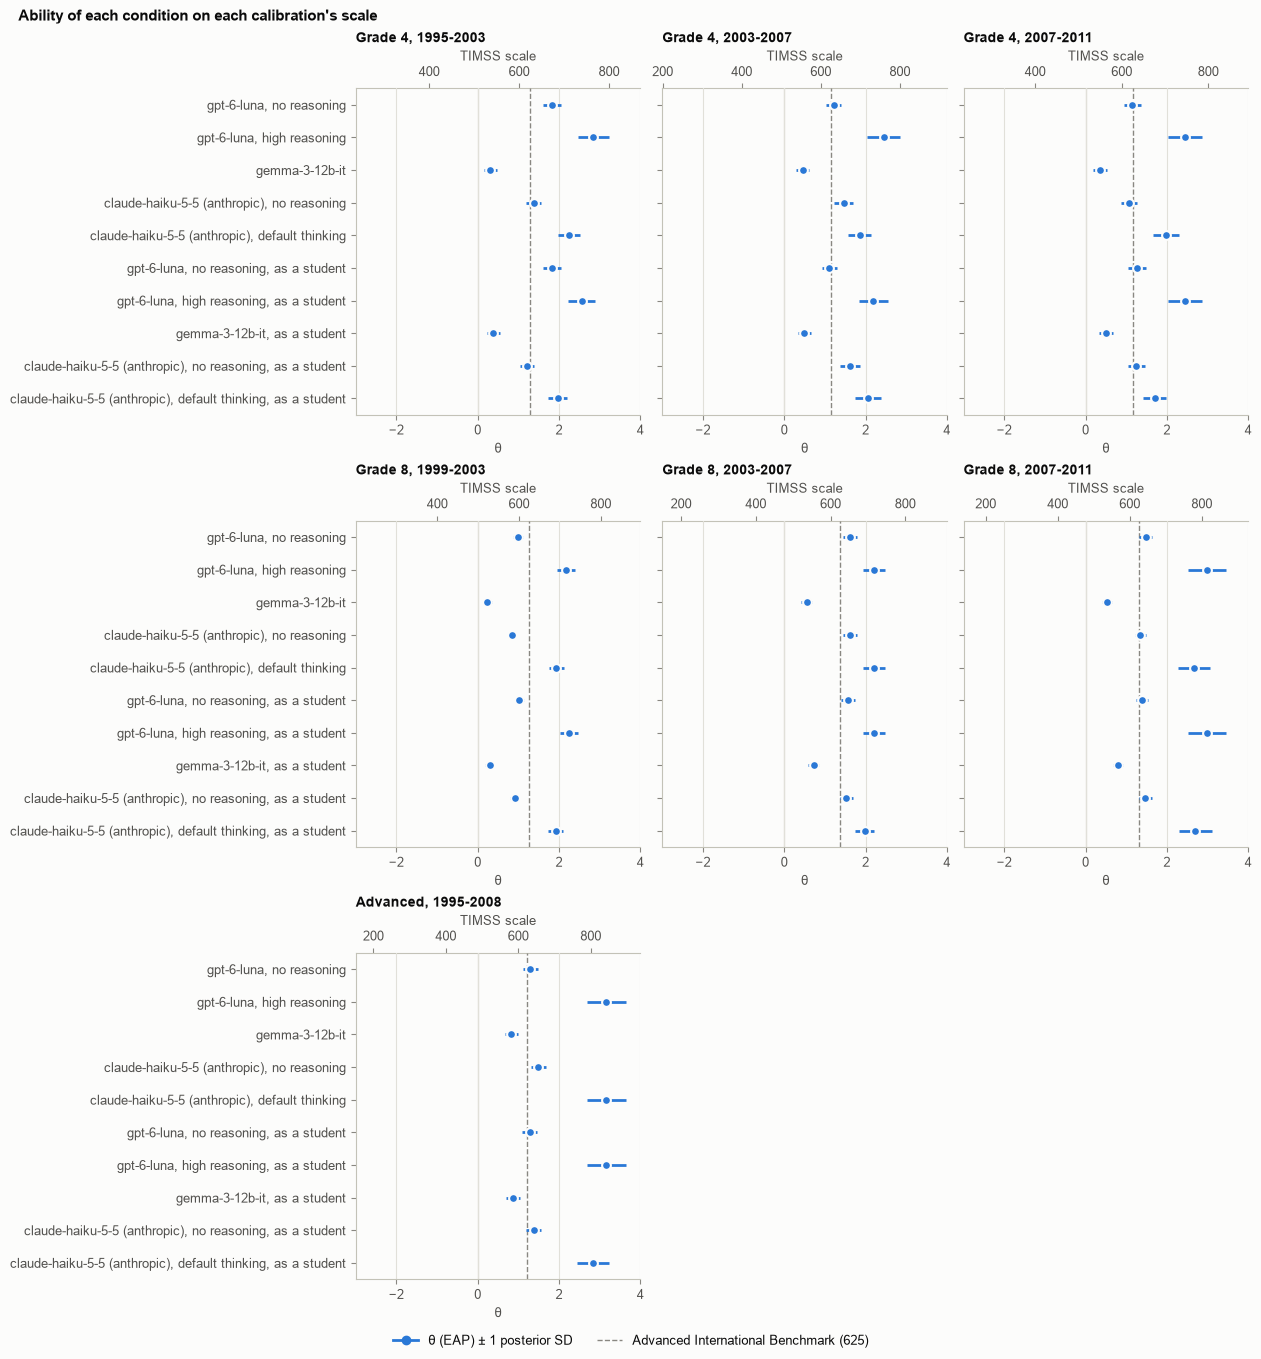

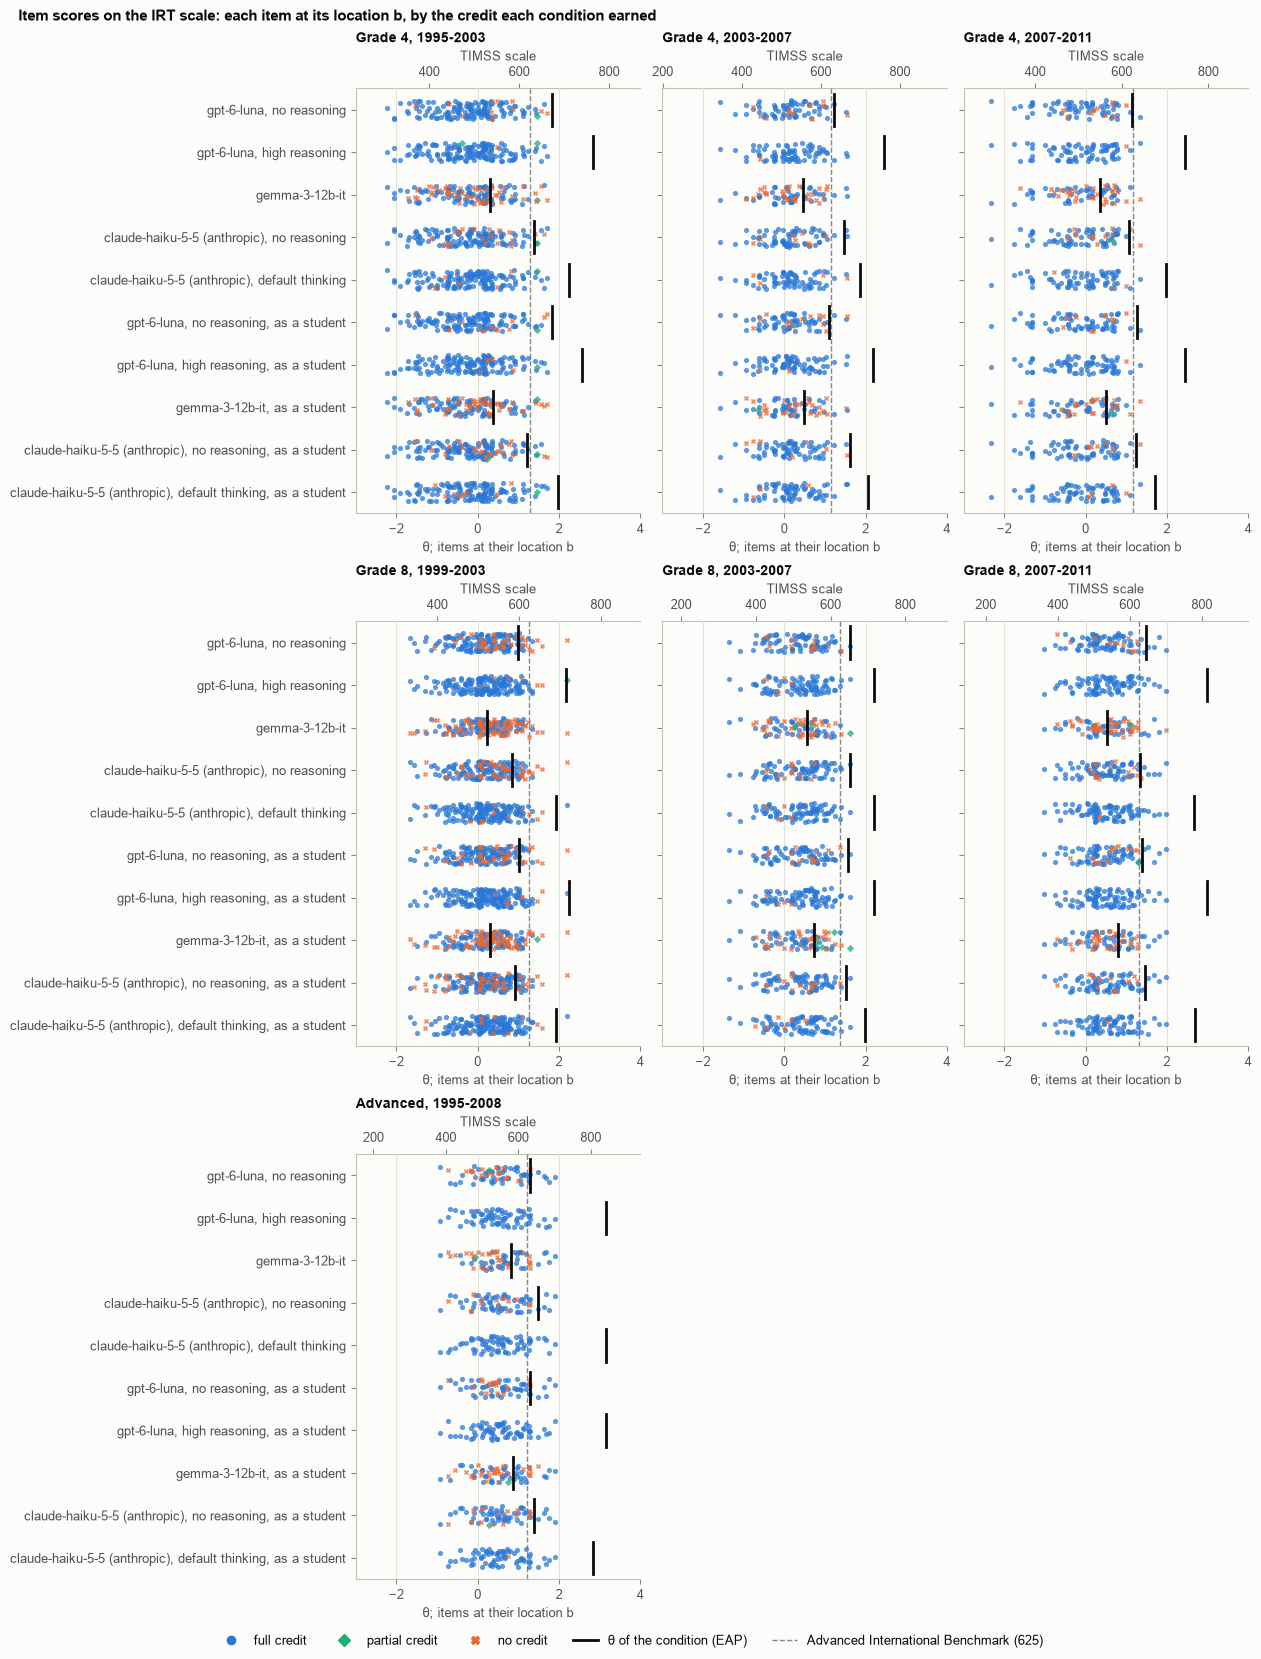

In [14]:
if results.overall.empty:
    print("No condition has a scored answer yet: request answers (MAX_REQUESTS) and verdicts (SCORER_MAX_REQUESTS)")
else:
    display(plots.theta_figure(results))
    display(plots.item_scores_figure(results))

## Two uses of the answers

The same answers serve two purposes, one per role:

1. **A benchmark** (`"test_taker"`): the released items are 724 tasks with an official key or scoring guide, whose difficulty for students in dozens of countries is known from their IRT parameters and percent correct.
   The questions are those of any benchmark: which LLM does best, by how much and at what cost, and on which tasks LLMs fail.
2. **Synthetic data** (`"student"`): each condition is a synthetic participant, an LLM told that it is a student of the grade, and its answers are a synthetic response pattern.
   Synthetic data are only as useful as they are like real students' data, so the questions are those of a validity check: do synthetic students answer as many items correctly as real students of their grade, do they find the same items hard, and do their response patterns fit the IRT models as real students' do.

Both use the item scores of the conditions (`results.item_scores`), the same table that the workbook's `item_scores` sheet holds, so they can also start from a saved workbook: `ScoringResults.read_excel("../results/timss_math_llm_answers_scored.xlsx")`.
A score here is the raw score of the scoring guide (`points` out of `max_points`), and a condition's percent of points is 100 Σ points / Σ maximum points over the items, as in `results.summary()`; its 95% confidence interval comes from resampling the items (`bootstrap_ci`).
Real students' data are the international average percent correct of each item (`pct_correct_intl_avg`, for 684 of the 724 items; TIMSS Advanced 2008 published none), which for an item worth 2 or 3 points is read as the percent of students with full credit, and the IRT parameters.

In [15]:
items = units.items_by_key
# One row per condition and scored item, with the role, the LLM (the condition without its role), full credit, whether
# the item has a figure, and real students' percent correct.
item_level = results.item_scores.assign(
    role=lambda frame: frame["condition"].map(results.conditions["role"]),
    llm=lambda frame: frame["condition"].str.removesuffix(", as a student"),
    full_credit=lambda frame: (frame["points"] == frame["max_points"]).astype(int),
    has_figure=lambda frame: frame["item_key"].map(lambda key: items[key]["has_figure"]),
    students_percent_correct=lambda frame: frame["item_key"].map(lambda key: items[key]["pct_correct_intl_avg"]).astype(float),
)
takers = item_level[item_level["role"] == "test_taker"]
students = item_level[item_level["role"] == "student"]
STUDENT_CONDITIONS = [condition for condition in results.conditions.index if condition in set(students["condition"])]
rng = np.random.default_rng(0)


def percent_of_points(frame: pd.DataFrame) -> float:
    return 100 * frame["points"].sum() / frame["max_points"].sum()


def bootstrap_ci(points, max_points, resamples: int = 2000) -> tuple[float, float]:
    """The 95% bootstrap confidence interval of 100 Σ points / Σ max_points, resampling the items. For a paired
    comparison, ``points`` is the difference of two conditions' points on each item."""
    points, max_points = np.asarray(points, dtype=float), np.asarray(max_points, dtype=float)
    picks = rng.integers(0, len(points), (resamples, len(points)))
    shares = 100 * points[picks].sum(axis=1) / max_points[picks].sum(axis=1)
    return tuple(np.percentile(shares, [2.5, 97.5]))


def by_condition(frame: pd.DataFrame, column: str | None = None) -> pd.DataFrame:
    """The percent of points of each condition in ``frame``, in the order of the conditions, by ``column`` if given."""
    keys = ["condition"] if column is None else ["condition", column]
    sums = frame.groupby(keys, sort=False)[["points", "max_points"]].sum()
    percent = 100 * sums["points"] / sums["max_points"]
    return percent.to_frame("percent_of_points") if column is None else percent.unstack(column).sort_index(axis=1)


print(f"{len(takers)} item scores of {takers['condition'].nunique()} test takers, {len(students)} of {students['condition'].nunique()} students")

3620 item scores of 5 test takers, 3619 of 5 students


## Use case 1: a benchmark, with LLMs as test takers

### The leaderboard

Each test-taking condition with its percent of points over all items and its 95% confidence interval, by grade, by format (multiple choice, scored against the key, and constructed response, scored by the LLM scorer), and by whether the item has a figure, which the LLM sees only described in words; then the range of its TIMSS scale scores (EAP) over the seven calibrations, the cost of its answers, and the output tokens per unit, reasoning included.

,percent_of_points,ci_low,ci_high,grade_4,grade_8,grade_12,constructed_response,multiple_choice,without_figure,with_figure,lowest_timss_eap,highest_timss_eap,cost_usd,output_tokens_per_unit
condition,,,,,,,,,,,,,,
"gpt-6-luna, high reasoning",97.6,96.3,98.7,98.4,96.4,100.0,96.2,98.6,98.4,96.5,715.3,843.2,0.043,191.6
"claude-haiku-5-5 (anthropic), default thinking",95.9,94.3,97.3,95.9,95.1,100.0,97.1,95.0,95.9,96.0,690.8,843.2,0.110,204.8
"gpt-6-luna, no reasoning",85.2,82.5,87.8,89.2,83.5,78.6,90.6,81.1,87.2,82.7,597.3,672.4,0.028,27.0
"claude-haiku-5-5 (anthropic), no reasoning",83.7,80.9,86.5,87.3,80.6,84.5,93.0,76.6,86.5,80.1,582.7,657.3,0.065,66.3
gemma-3-12b-it,60.0,56.4,63.7,64.3,55.8,63.1,61.3,59.0,63.2,55.9,522.1,581.0,0.017,64.7


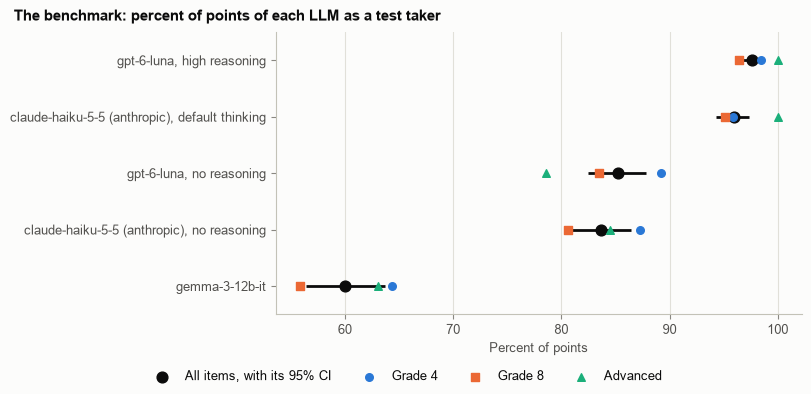

In [16]:
summary = results.summary()
leaderboard = by_condition(takers)
intervals = {condition: bootstrap_ci(group["points"], group["max_points"]) for condition, group in takers.groupby("condition", sort=False)}
leaderboard["ci_low"] = [intervals[condition][0] for condition in leaderboard.index]
leaderboard["ci_high"] = [intervals[condition][1] for condition in leaderboard.index]
leaderboard = leaderboard.join(by_condition(takers, "grade").rename(columns=lambda grade: f"grade_{grade}"))
leaderboard = leaderboard.join(by_condition(takers, "item_type")).join(
    by_condition(takers, "has_figure").rename(columns={True: "with_figure", False: "without_figure"})
)
leaderboard = leaderboard.join(summary[["lowest_timss_eap", "highest_timss_eap"]])
usage = results.conditions
leaderboard["cost_usd"] = (usage["direct_cost_usd"] + usage["batch_cost_usd"]).reindex(leaderboard.index)
leaderboard["output_tokens_per_unit"] = usage["mean_completion_tokens"].reindex(leaderboard.index)
leaderboard = leaderboard.sort_values("percent_of_points", ascending=False)
display(leaderboard.round(1).assign(cost_usd=leaderboard["cost_usd"].round(3)))


def leaderboard_figure(table: pd.DataFrame) -> Figure:
    """Each condition's percent of points with its 95% confidence interval, and by grade."""
    with matplotlib.rc_context(plot_style.STYLE):
        figure = Figure(figsize=(8, 0.45 * len(table) + 1.6), layout="constrained")
        ax = figure.subplots()
        positions = np.arange(len(table))
        ax.hlines(positions, table["ci_low"], table["ci_high"], color=plot_style.INK, linewidth=2, zorder=2)
        ax.scatter(table["percent_of_points"], positions, s=60, color=plot_style.INK, zorder=3, label="All items, with its 95% CI")
        for grade, (color, marker) in plot_style.GRADE_STYLES.items():
            if f"grade_{grade}" in table:
                ax.scatter(table[f"grade_{grade}"], positions, s=30, color=color, marker=marker, zorder=3, label=GRADE_SHORT_NAMES[grade])
        ax.set_yticks(positions, table.index)
        ax.set_ylim(len(table) - 0.5, -0.5)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Percent of points")
        figure.legend(loc="outside lower center", ncols=4)
        figure.suptitle("The benchmark: percent of points of each LLM as a test taker", x=0.01, ha="left", fontsize=11, fontweight="bold")
    return figure


if not leaderboard.empty:
    display(leaderboard_figure(leaderboard))

On the run of 2026-10-19, `gpt-6-luna` with high reasoning leads with 97.6% of the points (95% CI 96.3 to 98.7), ahead of `claude-haiku-5-5` with its default thinking (95.9%), the same two models without reasoning (85.2% and 83.7%), and `gemma-3-12b-it` (60.0%).

- **Reasoning nearly saturates the benchmark.** Both reasoning conditions earn every point of TIMSS Advanced and 95% or more at grades 4 and 8, so the items separate them by only about 2 points; harder items would be needed to tell such LLMs apart.
- **Format matters, in the opposite direction from students.** Without reasoning, the LLMs earn more of the points of constructed-response items than of multiple-choice items (`gpt-6-luna` 90.6% against 81.1%, `claude-haiku-5-5` 93.0% against 76.6%), while students' percent correct is about 15 points lower on constructed-response items (39% against 54% on average).
  Two reasons are possible, and a benchmark built on these items should allow for both: a constructed-response answer includes the work, which gives an LLM without reasoning room to think before it answers, while a multiple-choice answer is a letter alone; and constructed responses are scored by an LLM scorer, which may be lenient.
- **Figures cost the LLMs without reasoning 4 to 7 points** (`gpt-6-luna` 87.2% without a figure against 82.7% with one, `claude-haiku-5-5` 86.5% against 80.1%, `gemma-3-12b-it` 63.2% against 55.9%), since they see a figure only as a description, but not the reasoning conditions.
- **Cost.** All 652 units cost $0.017 (`gemma-3-12b-it`) to $0.110 (`claude-haiku-5-5` with its default thinking); the leader, `gpt-6-luna` with high reasoning, cost $0.043 in OpenRouter batches.

### Paired comparisons

All conditions answered the same items, so two of them are compared item by item: the difference in percent of points with its 95% confidence interval (resampling the items), and the items on which only one of them earned full credit.
The pairs are each model with and without reasoning, and each condition with the next one on the leaderboard.

In [17]:
def paired_comparison(first: str, second: str) -> dict:
    a = takers[takers["condition"] == first].set_index("item_key")
    b = takers[takers["condition"] == second].set_index("item_key")
    common = a.index.intersection(b.index)
    a, b = a.loc[common], b.loc[common]
    difference = a["points"] - b["points"]
    low, high = bootstrap_ci(difference, a["max_points"])
    return {
        "first": first,
        "second": second,
        "items": len(common),
        "difference": 100 * difference.sum() / a["max_points"].sum(),
        "ci_low": low,
        "ci_high": high,
        "full_credit_only_first": int(((a["full_credit"] == 1) & (b["full_credit"] == 0)).sum()),
        "full_credit_only_second": int(((a["full_credit"] == 0) & (b["full_credit"] == 1)).sum()),
    }


model_of = results.conditions["provider"] + "/" + results.conditions["model"]
pairs = [
    pair
    for _, group in leaderboard.index.to_series().groupby(model_of.reindex(leaderboard.index), sort=False)
    for pair in itertools.combinations(group, 2)  # in the order of the leaderboard
]
pairs += [pair for pair in zip(leaderboard.index[:-1], leaderboard.index[1:]) if pair not in pairs]
comparisons = pd.DataFrame([paired_comparison(first, second) for first, second in pairs])
display(comparisons.round(1))

,first,second,items,difference,ci_low,ci_high,full_credit_only_first,full_credit_only_second
0,"gpt-6-luna, high reasoning","gpt-6-luna, no reasoning",724,12.4,10.1,14.9,97,3
1,"claude-haiku-5-5 (anthropic), default thinking","claude-haiku-5-5 (anthropic), no reasoning",724,12.2,9.7,14.8,99,5
2,"gpt-6-luna, high reasoning","claude-haiku-5-5 (anthropic), default thinking",724,1.7,0.6,2.8,16,3
3,"claude-haiku-5-5 (anthropic), default thinking","gpt-6-luna, no reasoning",724,10.7,8.3,13.4,94,13
4,"gpt-6-luna, no reasoning","claude-haiku-5-5 (anthropic), no reasoning",724,1.5,-1.1,4.3,65,52
5,"claude-haiku-5-5 (anthropic), no reasoning",gemma-3-12b-it,724,23.7,19.7,27.5,206,35


On the run of 2026-10-19:

- **Reasoning adds about 12 points to both models**: 12.4 for `gpt-6-luna` (95% CI 10.1 to 14.9) and 12.2 for `claude-haiku-5-5` (9.7 to 14.8); with reasoning they earned full credit on 97 and 99 items that they missed without it, and lost it on 3 and 5.
- **The two reasoning conditions differ, but little**: `gpt-6-luna` with high reasoning is ahead of `claude-haiku-5-5` with its default thinking by 1.7 points (0.6 to 2.8), with full credit on 16 items that the other missed, against 3.
- **Equal scores hide different strengths**: without reasoning, `gpt-6-luna` and `claude-haiku-5-5` cannot be told apart (1.5 points, -1.1 to 4.3), yet each earned full credit on items that the other missed, 65 and 52 of them.

### Where LLMs fail, and where students fail

A benchmark built from a test for students can say more than a score: each item's difficulty for students is known, so the items that LLMs miss can be compared with the items that students miss.
For each item, the number of test-taking conditions with full credit is set against the international percent correct of students; a rank correlation near 0 means that what is hard for LLMs is not what is hard for students.
The table lists the items that most students answered correctly but that at most half of the LLMs did.

Rank correlation of the LLMs with full credit and the students' percent correct over 684 items: 0.15


,items,students_percent_correct,share_with_figure
llms_with_full_credit,,,
0,9,33.58,0.67
1,9,38.22,0.56
2,36,48.38,0.56
3,78,44.25,0.60
4,191,46.15,0.39
5,361,50.21,0.40


,item_id,assessment,grade,item_type,has_figure,students_percent_correct,llms_with_full_credit,llms
0,J3,TIMSS 1995,4,multiple_choice,True,75.0,2,5
1,L1,TIMSS Advanced 1995,12,multiple_choice,False,73.0,2,5
2,M041052,TIMSS 2007,4,multiple_choice,False,70.5,1,5
3,M031135,TIMSS 2007,4,multiple_choice,True,65.8,0,5
4,J17,TIMSS 1999,8,multiple_choice,False,65.0,2,5
5,H07,TIMSS 1999,8,multiple_choice,True,64.0,2,5
6,M011017,TIMSS 2003,4,multiple_choice,False,64.0,2,5
7,M041158,TIMSS 2011,4,multiple_choice,True,63.0,2,5
8,L2,TIMSS Advanced 1995,12,multiple_choice,False,63.0,2,5


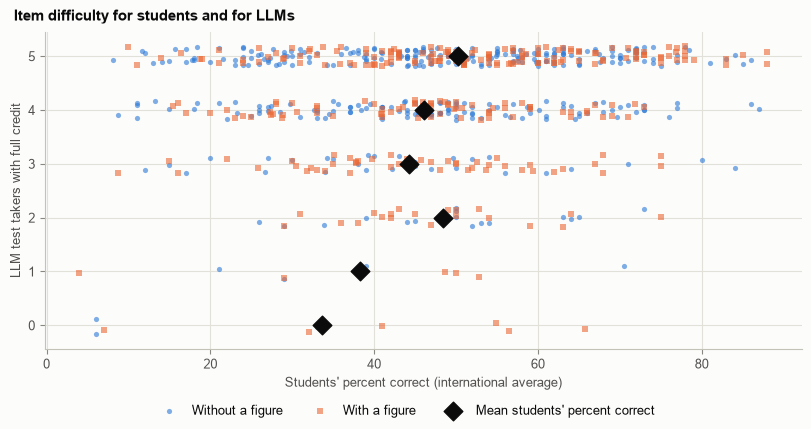

In [18]:
per_item = (
    takers.dropna(subset=["students_percent_correct"])
    .groupby("item_key")
    .agg(
        item_id=("item_id", "first"),
        assessment=("assessment", "first"),
        grade=("grade", "first"),
        item_type=("item_type", "first"),
        has_figure=("has_figure", "first"),
        students_percent_correct=("students_percent_correct", "first"),
        llms_with_full_credit=("full_credit", "sum"),
        llms=("full_credit", "size"),
    )
)
correlation = stats.spearmanr(per_item["llms_with_full_credit"], per_item["students_percent_correct"]).statistic
print(f"Rank correlation of the LLMs with full credit and the students' percent correct over {len(per_item)} items: {correlation:.2f}")
display(
    per_item.groupby("llms_with_full_credit").agg(
        items=("item_id", "size"),
        students_percent_correct=("students_percent_correct", "mean"),
        share_with_figure=("has_figure", "mean"),
    ).round(2)
)
easy_for_students = per_item[(per_item["students_percent_correct"] >= 60) & (per_item["llms_with_full_credit"] <= per_item["llms"] / 2)]
display(easy_for_students.sort_values("students_percent_correct", ascending=False).reset_index(drop=True))


def difficulty_figure(table: pd.DataFrame) -> Figure:
    """Each item's percent correct for students against the LLMs with full credit, by whether it has a figure."""
    with matplotlib.rc_context(plot_style.STYLE):
        figure = Figure(figsize=(8, 4.2), layout="constrained")
        ax = figure.subplots()
        jitter = np.random.default_rng(3).uniform(-0.18, 0.18, len(table))
        for has_figure, color, marker, label in ((False, plot_style.SERIES[0], "o", "Without a figure"), (True, plot_style.SERIES[1], "s", "With a figure")):
            chosen = (table["has_figure"] == has_figure).to_numpy()
            ax.scatter(table["students_percent_correct"][chosen], (table["llms_with_full_credit"] + jitter)[chosen], s=14, color=color, marker=marker, alpha=0.6, linewidths=0, label=label)
        means = table.groupby("llms_with_full_credit")["students_percent_correct"].mean()
        ax.scatter(means, means.index, s=90, color=plot_style.INK, marker="D", zorder=3, label="Mean students' percent correct")
        ax.set_xlabel("Students' percent correct (international average)")
        ax.set_ylabel("LLM test takers with full credit")
        ax.set_yticks(range(int(table["llms"].max()) + 1))
        figure.legend(loc="outside lower center", ncols=3)
        figure.suptitle("Item difficulty for students and for LLMs", x=0.01, ha="left", fontsize=11, fontweight="bold")
    return figure


if not per_item.empty:
    display(difficulty_figure(per_item))

On the run of 2026-10-19, the rank correlation is 0.15: the items that the LLMs miss are only a little harder for students.
The 361 items that all five test takers answered fully correctly were answered correctly by 50% of students on average, and the 9 that none of them did by 34%.
Items with a figure make up 56% to 67% of the items that at most three LLMs answered fully, against 39% to 40% of those that four or five did.
Nine items that 60% or more of students answered correctly were answered fully by at most two of the five LLMs; all are multiple choice, and four have a figure (J3 and M031135 of grade 4, H07 of grade 8, and M041158 of grade 4).
These are the items where a benchmark of LLMs and a test of students disagree most.

## Use case 2: synthetic data, with LLMs as students

In the student role, each condition is one synthetic participant, and its scores on the items are a synthetic response pattern.
Before such data stand in for students' data, they should resemble them, which the analyses below check against what is known about real students:

1. **Percent correct by grade**: do synthetic fourth, eighth, and twelfth graders answer as many items correctly as real students of their grade?
2. **The role**: does telling the LLM that it is a student change its answers at all, compared with the same LLM as a test taker?
3. **Item difficulty**: do synthetic students miss the items that real students miss?
4. **Response patterns**: do their patterns fit the IRT models as real students' do, and where would their ability place them among real students?
5. **The same item at two grades**: two items were given to both fourth and eighth graders; do synthetic students of the two grades differ on them as real students do?

### Percent correct by grade

The raw scores across all the released items, by the grade of the test: the percent of points of each synthetic student, and, on the items with real students' statistics, its percent of items with full credit against real students' average percent correct.

Percent correct (full credit) on the items with real students' statistics, by grade:


,Grade 4 (296 items),Grade 8 (357 items),Advanced (31 items)
real students (international average),52.4,44.7,42.7
"gpt-6-luna, no reasoning, as a student",88.2,82.1,74.2
"gpt-6-luna, high reasoning, as a student",97.3,97.2,100.0
"gemma-3-12b-it, as a student",66.2,59.7,53.3
"claude-haiku-5-5 (anthropic), no reasoning, as a student",86.8,81.2,71.0
"claude-haiku-5-5 (anthropic), default thinking, as a student",94.6,95.0,100.0


Percent of points over all the released items, by grade:


grade,Grade 4,Grade 8,Advanced
condition,,,
"gpt-6-luna, no reasoning, as a student",88.5,82.2,78.6
"gpt-6-luna, high reasoning, as a student",97.5,96.6,100.0
"gemma-3-12b-it, as a student",67.2,61.2,64.2
"claude-haiku-5-5 (anthropic), no reasoning, as a student",87.3,81.9,82.1
"claude-haiku-5-5 (anthropic), default thinking, as a student",94.6,94.6,98.8


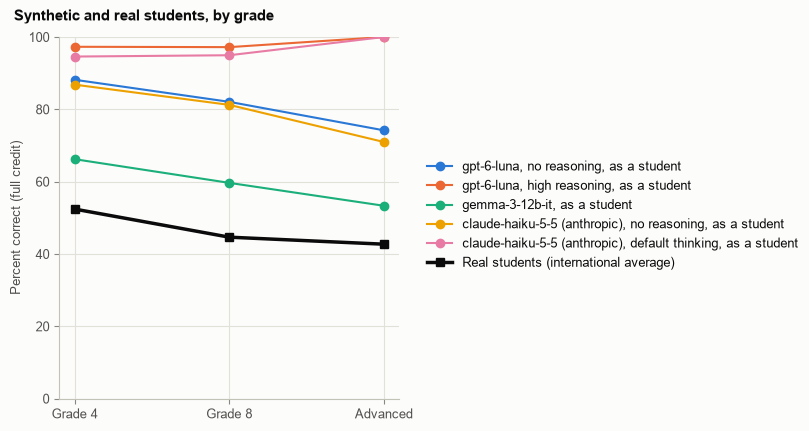

In [19]:
with_statistics = students.dropna(subset=["students_percent_correct"])
unique_items = with_statistics.drop_duplicates("item_key")
real_students = unique_items.groupby("grade")["students_percent_correct"].mean().rename("real students (international average)")
full_credit_by_grade = 100 * with_statistics.pivot_table(index="condition", columns="grade", values="full_credit").reindex(STUDENT_CONDITIONS)
counts = unique_items.groupby("grade").size()
grade_table = pd.concat([real_students.to_frame().T, full_credit_by_grade])
grade_table.columns = [f"{GRADE_SHORT_NAMES[grade]} ({counts[grade]} items)" for grade in grade_table.columns]
print("Percent correct (full credit) on the items with real students' statistics, by grade:")
display(grade_table.round(1))
print("Percent of points over all the released items, by grade:")
display(by_condition(students, "grade").rename(columns=GRADE_SHORT_NAMES).round(1))


def grade_figure(table: pd.DataFrame, real: pd.Series) -> Figure:
    """Each synthetic student's percent with full credit by grade (a row of ``table``), against real students' percent
    correct."""
    with matplotlib.rc_context(plot_style.STYLE):
        figure = Figure(figsize=(8, 4.2), layout="constrained")
        ax = figure.subplots()
        grades = list(real.index)
        positions = np.arange(len(grades))
        for number, condition in enumerate(table.index):
            color = plot_style.SERIES[number % len(plot_style.SERIES)]
            ax.plot(positions, table.loc[condition, grades], marker="o", color=color, linewidth=1.5, label=condition)
        ax.plot(positions, real.loc[grades], marker="s", color=plot_style.INK, linewidth=2.5, label="Real students (international average)")
        ax.set_xticks(positions, [GRADE_SHORT_NAMES[grade] for grade in grades])
        ax.set_ylim(0, 100)
        ax.set_ylabel("Percent correct (full credit)")
        figure.legend(loc="outside right center")
        figure.suptitle("Synthetic and real students, by grade", x=0.01, ha="left", fontsize=11, fontweight="bold")
    return figure


if not with_statistics.empty:
    display(grade_figure(full_credit_by_grade, real_students))

On the run of 2026-10-19, real students answered 52% of the fourth-grade items correctly on average, 45% of the eighth-grade items, and 43% of the TIMSS Advanced items (of 1995; TIMSS Advanced 2008 published no percent correct).
Every synthetic student did better at every grade, even `gemma-3-12b-it` (66%, 60%, and 53%), and the two reasoning conditions answered about 95% to 100% fully.
The synthetic students without reasoning decline from grade 4 to grade 8 to TIMSS Advanced as real students do (`gpt-6-luna` 88%, 82%, and 74%), but so do the same LLMs as test takers, so the decline reflects the items, not the role; the reasoning conditions do not decline at all.

### Does the student role change the answers?

Each LLM that took the test in both roles, as a test taker and as a student, compared item by item within each grade: its percent of points in each role, and the difference (student minus test taker) with its 95% confidence interval.

In [20]:
both_roles = sorted(set(takers["llm"]) & set(students["llm"]), key=list(item_level["llm"]).index)
rows = []
for llm in both_roles:
    paired = item_level[item_level["llm"] == llm].pivot_table(index=["item_key", "grade"], columns="role", values=["points", "max_points"]).dropna()
    for grade, group in paired.groupby(level="grade"):
        difference = group[("points", "student")] - group[("points", "test_taker")]
        low, high = bootstrap_ci(difference, group[("max_points", "student")])
        total = group[("max_points", "student")].sum()
        rows.append(
            {
                "llm": llm,
                "grade": grade,
                "items": len(group),
                "test_taker": 100 * group[("points", "test_taker")].sum() / total,
                "student": 100 * group[("points", "student")].sum() / total,
                "difference": 100 * difference.sum() / total,
                "ci_low": low,
                "ci_high": high,
            }
        )
role_effect = pd.DataFrame(rows)
display(role_effect.round(1))

,llm,grade,items,test_taker,student,difference,ci_low,ci_high
0,"gpt-6-luna, no reasoning",4,296,89.2,88.5,-0.6,-3.1,1.9
1,"gpt-6-luna, no reasoning",8,357,83.5,82.2,-1.3,-4.7,1.9
2,"gpt-6-luna, no reasoning",12,71,78.6,78.6,0.0,-6.2,6.4
3,"gpt-6-luna, high reasoning",4,296,98.4,97.5,-1.0,-2.6,0.6
4,"gpt-6-luna, high reasoning",8,357,96.4,96.6,0.3,-0.5,1.1
5,"gpt-6-luna, high reasoning",12,71,100.0,100.0,0.0,0.0,0.0
6,gemma-3-12b-it,4,296,64.3,67.2,2.9,-1.3,7.3
7,gemma-3-12b-it,8,357,55.8,61.2,5.4,1.3,9.4
8,gemma-3-12b-it,12,70,61.7,64.2,2.5,-5.1,10.3
9,"claude-haiku-5-5 (anthropic), no reasoning",4,296,87.3,87.3,0.0,-2.8,2.6


On the run of 2026-10-19, the student role changes almost nothing: for four of the five LLMs every difference is within 2.4 points, and every confidence interval includes 0.
Only `gemma-3-12b-it` does better as a student, by 5.4 points at grade 8 (95% CI 1.3 to 9.4).
Told that it is a fourth-grade student, an LLM still answers as well as it can: the role sets the frame of the test, not the knowledge or the mistakes of a fourth grader.

### Do synthetic students find the same items hard?

Real students' percent correct orders the items from easy to hard.
For data to stand in for students' data, synthetic students should succeed more often on the items that students find easy: the rank correlation of a condition's full credit with students' percent correct should be clearly positive, and higher for synthetic students than for test takers if the role makes the LLM more like a student.
The graph bins the items by students' percent correct (ten bins of about equal size) and shows each synthetic student's percent with full credit in each bin; a synthetic student like the average real student would follow the diagonal.

"rank correlation with students' percent correct, by role",test_taker,student
llm,,
"gpt-6-luna, no reasoning",0.112,0.101
"gpt-6-luna, high reasoning",0.095,0.082
gemma-3-12b-it,0.124,0.139
"claude-haiku-5-5 (anthropic), no reasoning",0.077,0.009
"claude-haiku-5-5 (anthropic), default thinking",0.028,-0.023


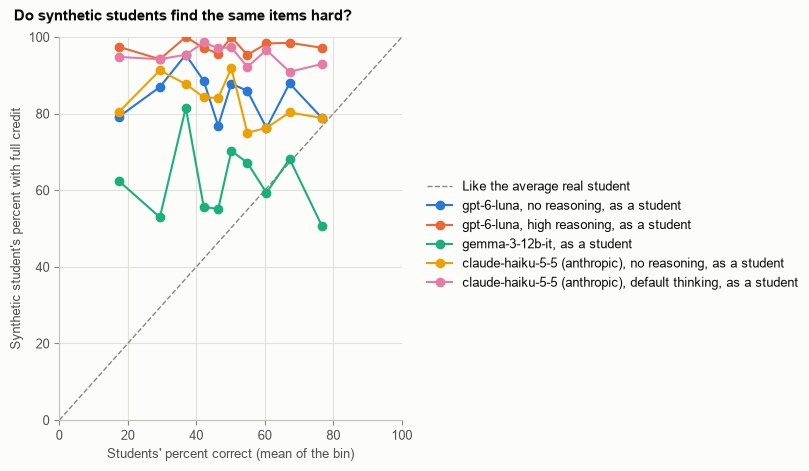

In [21]:
alignment = (
    item_level.dropna(subset=["students_percent_correct"])
    .groupby(["llm", "role"], sort=False)
    .apply(lambda group: stats.spearmanr(group["full_credit"], group["students_percent_correct"]).statistic, include_groups=False)
    .unstack("role")
)
display(alignment.round(3).rename_axis(columns="rank correlation with students' percent correct, by role"))


def calibration_figure(frame: pd.DataFrame, bins: int = 10) -> Figure:
    """Each synthetic student's percent with full credit in bins of items by students' percent correct."""
    item_bins = pd.qcut(frame.drop_duplicates("item_key").set_index("item_key")["students_percent_correct"], bins, duplicates="drop")
    binned = frame.assign(bin=frame["item_key"].map(item_bins))
    real = binned.drop_duplicates("item_key").groupby("bin", observed=True)["students_percent_correct"].mean()
    synthetic = 100 * binned.pivot_table(index="bin", columns="condition", values="full_credit", observed=True, sort=False)
    with matplotlib.rc_context(plot_style.STYLE):
        figure = Figure(figsize=(8, 4.6), layout="constrained")
        ax = figure.subplots()
        ax.plot([0, 100], [0, 100], color=plot_style.INK_MUTED, linewidth=1, linestyle="--", label="Like the average real student")
        for number, condition in enumerate(synthetic.columns):
            ax.plot(real, synthetic[condition], marker="o", color=plot_style.SERIES[number % len(plot_style.SERIES)], linewidth=1.5, label=condition)
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)
        ax.set_xlabel("Students' percent correct (mean of the bin)")
        ax.set_ylabel("Synthetic student's percent with full credit")
        figure.legend(loc="outside right center")
        figure.suptitle("Do synthetic students find the same items hard?", x=0.01, ha="left", fontsize=11, fontweight="bold")
    return figure


if not with_statistics.empty:
    display(calibration_figure(with_statistics))

On the run of 2026-10-19, the rank correlations are 0.14 at most, and the student role lowers them for four of the five LLMs (for `claude-haiku-5-5` without reasoning, from 0.08 to 0.01).
In the graph, the synthetic students' percent with full credit hardly rises from the items that few students answer (left) to those that most students answer (right), whereas the average real student follows the diagonal: the synthetic students are not only too able, their difficulties are not students' difficulties.

### Do their response patterns look like students'?

Two checks on each synthetic student and calibration, from the IRT models:

- **Person fit**, the standardized log-likelihood l<sub>z</sub> of the response pattern at the condition's θ (EAP): for real students who respond as the IRT model says, l<sub>z</sub> is about standard normal, and a value below about -2 flags a pattern that misses easy items while solving hard ones.
  It is computed at an estimated θ, so it is only approximately standard normal, and a near-perfect pattern says little.
- **Percentile**: on each calibration's θ scale, the students of the calibration have about mean 0 and standard deviation 1, so Φ(θ) places a synthetic student among them.

In [22]:
def person_fit(keys, scores, theta: float) -> float:
    """The standardized log-likelihood l_z of a response pattern at θ, for dichotomous and polytomous items."""
    observed = expected = variance = 0.0
    for key, score in zip(keys, scores):
        probabilities = administration.models[key].probabilities(theta)[0]
        logs = np.log(np.clip(probabilities, 1e-300, None))
        mean = probabilities @ logs
        observed += logs[int(score)]
        expected += mean
        variance += probabilities @ logs**2 - mean**2
    return (observed - expected) / np.sqrt(variance)


fit = (
    item_level.groupby(["condition", "calibration"], sort=False)
    .apply(lambda group: person_fit(group["item_key"], group["score"], group["theta_eap"].iloc[0]), include_groups=False)
    .unstack("calibration")
    .reindex(columns=list(results.calibrations.index))
)
print("Person fit l_z, by condition (students and, for comparison, test takers) and calibration:")
display(fit.round(2))
percentile = results.overall.assign(percentile=lambda frame: 100 * stats.norm.cdf(frame["theta_eap"]))
print("Percentile among the calibration's students, Φ(θ EAP), of each synthetic student:")
display(
    percentile[percentile["role"] == "student"]
    .pivot(index="condition", columns="calibration", values="percentile")
    .reindex(index=STUDENT_CONDITIONS, columns=list(results.calibrations.index))
    .round(1)
)

Person fit l_z, by condition (students and, for comparison, test takers) and calibration:


calibration,"Grade 4, 1995-2003","Grade 4, 2003-2007","Grade 4, 2007-2011","Grade 8, 1999-2003","Grade 8, 2003-2007","Grade 8, 2007-2011","Advanced, 1995-2008"
condition,,,,,,,
"gpt-6-luna, no reasoning",0.40,-0.76,-0.44,-0.52,-0.54,-0.64,-3.41
"gpt-6-luna, high reasoning",0.94,0.27,1.10,0.98,-0.50,1.23,1.46
gemma-3-12b-it,-4.00,-3.35,-2.35,-4.10,-4.84,-3.36,-5.11
"claude-haiku-5-5 (anthropic), no reasoning",-0.79,-0.75,-0.07,-1.87,-1.57,-1.20,-2.06
"claude-haiku-5-5 (anthropic), default thinking",-0.01,-0.12,0.39,0.24,-0.50,0.51,1.46
"gpt-6-luna, no reasoning, as a student",0.12,-0.66,-0.53,-1.24,-0.88,-1.20,-3.11
"gpt-6-luna, high reasoning, as a student",0.89,-0.08,1.10,1.10,-0.50,1.23,1.46
"gemma-3-12b-it, as a student",-2.62,-2.60,-0.80,-4.98,-2.80,-4.23,-4.84
"claude-haiku-5-5 (anthropic), no reasoning, as a student",-0.88,-0.90,-0.22,-3.40,-1.31,-1.58,-2.09


Percentile among the calibration's students, Φ(θ EAP), of each synthetic student:


calibration,"Grade 4, 1995-2003","Grade 4, 2003-2007","Grade 4, 2007-2011","Grade 8, 1999-2003","Grade 8, 2003-2007","Grade 8, 2007-2011","Advanced, 1995-2008"
condition,,,,,,,
"gpt-6-luna, no reasoning, as a student",96.7,86.6,89.6,84.6,94.1,91.9,89.9
"gpt-6-luna, high reasoning, as a student",99.5,98.6,99.3,98.8,98.6,99.9,99.9
"gemma-3-12b-it, as a student",65.1,68.7,69.3,61.5,76.6,78.8,80.7
"claude-haiku-5-5 (anthropic), no reasoning, as a student",88.8,94.7,89.5,81.8,93.7,93.0,91.5
"claude-haiku-5-5 (anthropic), default thinking, as a student",97.5,98.0,95.5,97.2,97.6,99.7,99.8


On the run of 2026-10-19:

- **`gemma-3-12b-it` responds unlike a student.** As a student its l<sub>z</sub> is below -2 on six of the seven calibrations (down to -5.0): it misses items that students of its estimated ability nearly always answer, and answers harder ones.
  `claude-haiku-5-5` without reasoning misfits on two calibrations as a student, and `gpt-6-luna` without reasoning on one; the patterns of the reasoning conditions fit, but they are nearly perfect, which says little.
- **Every synthetic student is above the median real student on every calibration**: `gemma-3-12b-it` at the 62nd to 81st percentile, the two LLMs without reasoning at the 82nd to 97th, and the two with reasoning at the 96th to 99.9th.

### The same item at two grades

Two items appear word for word in a fourth-grade and an eighth-grade test (`DUPLICATE_ITEMS`), so real students of both grades answered them: eighth graders did better.
A synthetic student that answers as a student of its grade should also do better on the eighth-grade copy.

In [23]:
two_grades = {copy: original for copy, original in DUPLICATE_ITEMS.items() if items[copy]["grade"] != items[original]["grade"]}
rows = []
for copy, original in two_grades.items():
    pair = sorted([copy, original], key=lambda key: items[key]["grade"])
    row = {"items": " and ".join(f"{items[key]['item_id']} ({items[key]['assessment']}, grade {items[key]['grade']})" for key in pair)}
    row |= {f"real students, grade {items[key]['grade']}": items[key]["pct_correct_intl_avg"] for key in pair}
    for condition, group in students[students["item_key"].isin(pair)].groupby("condition", sort=False):
        credit = group.set_index("item_key")["full_credit"]
        row[condition] = " / ".join(str(credit.get(key, "-")) for key in pair)
    rows.append(row)
display(pd.DataFrame(rows).set_index("items").T)

items,"K7 (TIMSS 1995, grade 4) and M012030 (TIMSS 2003, grade 8)","M012023 (TIMSS 2003, grade 4) and D11 (TIMSS 1999, grade 8)"
"real students, grade 4",23,69
"real students, grade 8",37,81
"gpt-6-luna, no reasoning, as a student",1 / 1,1 / 1
"gpt-6-luna, high reasoning, as a student",1 / 1,1 / 1
"gemma-3-12b-it, as a student",0 / 0,1 / 1
"claude-haiku-5-5 (anthropic), no reasoning, as a student",1 / 1,1 / 1
"claude-haiku-5-5 (anthropic), default thinking, as a student",1 / 1,1 / 1


On the run of 2026-10-19, real eighth graders did 14 and 12 points better than fourth graders on the same items, while every synthetic student scored the two copies of each item alike: all of them answered both copies of M012023 correctly, and all but `gemma-3-12b-it`, which missed both, answered both copies of K7.
The grade in the system prompt changed none of the answers.

### The synthetic response matrix

The synthetic data themselves: one row per synthetic student and one column per item, with its score in the scaling, as an IRT program or a classical item analysis takes them.

In [24]:
synthetic_matrix = students.pivot(index="condition", columns="item_key", values="score").reindex(
    index=STUDENT_CONDITIONS, columns=list(units.parameters.index)
)
print(f"{synthetic_matrix.shape[0]} synthetic students by {synthetic_matrix.shape[1]} items, {int(synthetic_matrix.isna().sum().sum())} scores missing")
display(synthetic_matrix.iloc[:, :8])

5 synthetic students by 724 items, 1 scores missing


item_key,TIMSS 1995/grade 4/Mathematics/I3,TIMSS 1995/grade 4/Mathematics/I4,TIMSS 1995/grade 4/Mathematics/I9,TIMSS 1995/grade 4/Mathematics/J4,TIMSS 1995/grade 4/Mathematics/J9,TIMSS 1995/grade 4/Mathematics/K2,TIMSS 1995/grade 4/Mathematics/L7,TIMSS 1995/grade 4/Mathematics/M3
condition,,,,,,,,
"gpt-6-luna, no reasoning, as a student",1,1,1,1,1,0,1,1
"gpt-6-luna, high reasoning, as a student",1,1,1,1,1,1,1,1
"gemma-3-12b-it, as a student",1,1,0,0,0,0,0,1
"claude-haiku-5-5 (anthropic), no reasoning, as a student",0,1,1,0,1,0,1,1
"claude-haiku-5-5 (anthropic), default thinking, as a student",1,1,0,1,1,1,1,1


### What these synthetic data are, and what personas would add

The five synthetic students are five LLM settings, not five students: each answers as well as it can whatever grade it is told, its answers barely depend on the role, its difficulties are not students' difficulties, and four of the five rank near the top of real students.
Synthetic data that stand in for a population of students need variation that the role alone does not give:

- **Personas.** A student prompt with a persona, such as a student at a given International Benchmark, with the typical misconceptions of the grade, or taught a given country's curriculum, makes each persona a synthetic participant, and repeated answers of each persona (sampling) give a distribution rather than one pattern.
  This needs a change to the modules: a persona on a condition, which the student system prompt includes and which names the condition's label and cache folder.
- **The same checks.** The analyses above tell whether personas come closer to real students: their percent correct by grade, their rank correlation with students' percent correct, their person fit, and their spread on the θ scale.
- **A caveat.** A persona told to perform at a lower level may make up mistakes that real students do not make; the alignment and person-fit checks are the guard against it.

The benchmark needs no such change: its tasks, keys, scoring guides, and the students' statistics are all in the package, and any LLM of `LLMSettings` can be added to `MODELS`.

## Export

`WORKBOOK`, `data/timss_math_llm_answers_scored.xlsx` by default (`ScoringResults.to_excel`), holds the conditions with their settings, role, usage, and cost (`conditions`), the θ and TIMSS scale score of each condition and calibration (`overall_scores`, and `theta_eap` and `timss_eap` as tables), the item scores on the IRT scale with every answer and verdict and the item's calibrated parameters, their standard errors, and their source (`item_scores`, and `item_scores_wide` with one column per condition), and the calibrations with their TIMSS scale constants (`calibrations`).
`ScoringResults.read_excel` reads it back, such as to draw its graphs without the saved answers.

In [25]:
print(f"Wrote {results.to_excel(WORKBOOK).name}")

Wrote timss_math_llm_answers_scored.xlsx
